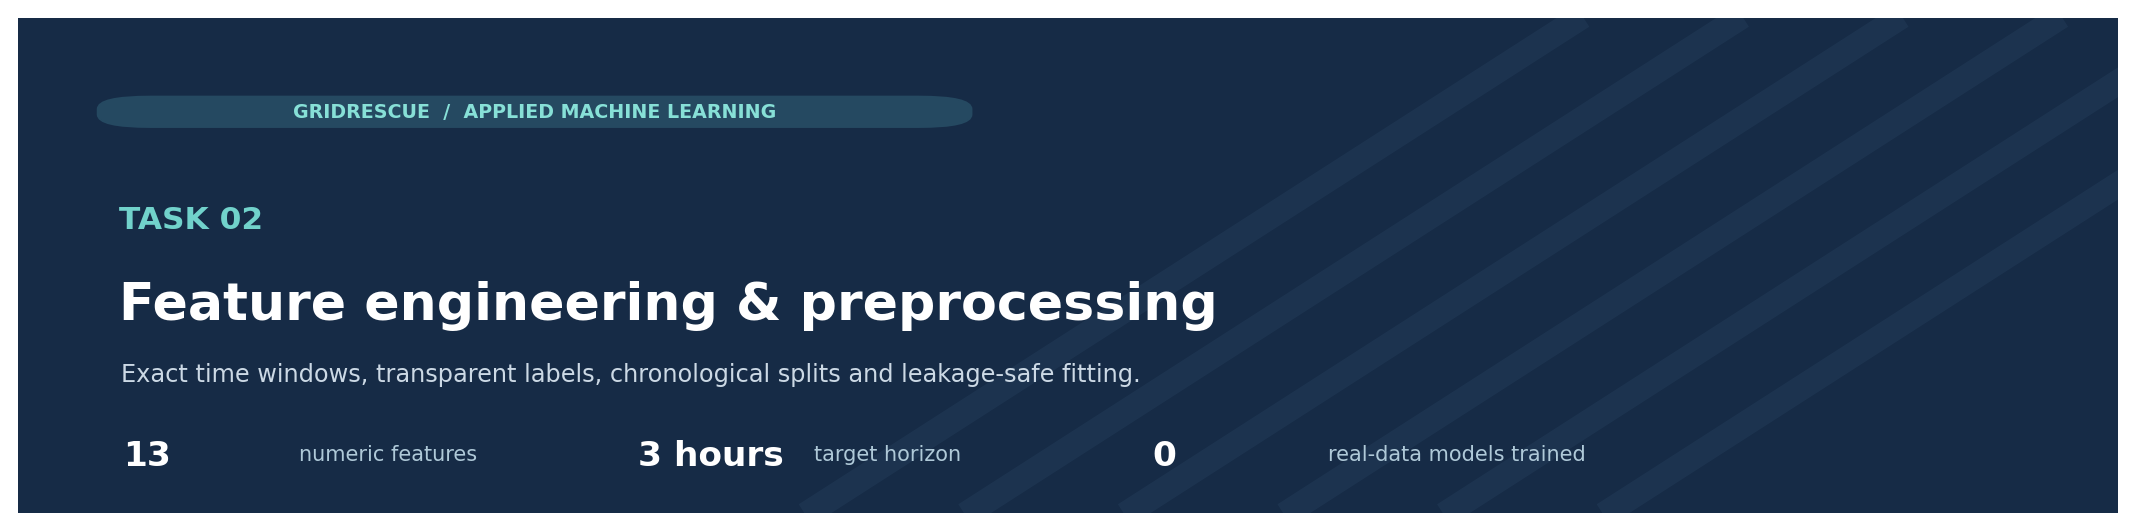

*GridRescue · saved executed results · project-specific scope limitations apply*

# GridRescue · Task 02 — Feature Engineering & Preprocessing

> **Scope:** EDA and preprocessing use 2018–2021 development data. The 2022 holdout stays sealed.

**Predictive task:** For a county with a positive currently reported outage count, predict whether the count rises by at least `max(200, 50% of current_count)` in a fully observed future three-hour window. Every eligible label requires twelve exact 15-minute observations; missing future reports are never treated as negatives.

**X contract:** Thirteen ordered numeric features computed from anchor-time or earlier information; county and state remain grouping/audit metadata. No future target calculations are used as predictors.

### Navigate directly to a section

| Jump to section | Focus |
|---|---|
| [01 · Feature engineering](#task2-features) | Definitions, exact lags, missingness and leakage prevention |
| [02 · Target and chronological split](#task2-splitting) | Complete future windows, exclusion rules and boundary purge |
| [03 · Preprocessing](#task2-preprocessing) | Median imputation, vector assembly, StandardScaler and before/after |
| [03A · Full-year county modeling preparation](#task2-county-modeling) | Separate county training statistics and feature-contract assertions |
| [03B · Original county evidence](#task2-county-summary) | Retained executed audit tables and visual summaries |
| [04 · Final checks and persistence](#task2-checks) | Feature validation, artifacts and integrity checks |

### Understand the four data scopes

| Data scope | Which observations? | Why we use it |
|---|---|---|
| **Original EAGLE-I source** | 2018–2022, 122,019,012 data records plus five headers in the audited file inventory | Data provenance and scale; 2022 is sealed for final ML assessment |
| **Full development-source integrity audit** | 2018–2021, 96,222,547 parsed records | Spark schema, null and invalid-token checks before nationwide deduplication |
| **January-prefix sample** | First 100,000 source rows in each 2018–2021 year; 400,000 January raw rows | Detailed reproducible Spark, EDA and preprocessing examples; **not** nationally representative |
| **Full-year three-county development cohort** | Los Angeles (06037), Miami-Dade (12086), Harris (48201), 2018–2021 | Separate primary modeling population, all months represented in available observations; **not** nationally representative |

**Do not concatenate the January and county cohorts:** their source rows overlap. "All months represented" never means that every 15-minute county-time slot is observed. The 2022 modeling holdout is not loaded in these notebooks.

**Why StandardScaler?** Useful for Logistic Regression optimization and regularization when magnitudes differ; MinMaxScaler is also valid. **Neither** is outlier-resistant, and tree-based models generally do not need scaling. Preprocessing is learned on training data only and refit independently within each Task 3 CV fold.


In [1]:
from pathlib import Path
import sys, json, os
# Search upward so this works from the project root or notebooks folder.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/gridrescue/pipeline.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Open the notebook from the GridRescue repository.')
sys.path.insert(0, str(ROOT / 'src'))
from gridrescue.pipeline import make_spark, read_source, clean, features, audit_labels, fit_preparation, PREDICTORS, SOURCE
from pyspark.sql import functions as F, Window
from gridrescue.storage import read_frame,load_preparation,scope_paths
from IPython.display import display, Markdown
import matplotlib.pyplot as plt
# Start a local Spark session with UTC timestamps.
spark = make_spark('GridRescue coursework')
BASE = ROOT / 'artifacts/sample'
SILVER = ROOT / 'data/silver/sample'
GOLD = ROOT / 'data/gold/sample/features'
LABELS = ROOT / 'data/gold/sample/label_audit'
MODE = os.environ.get('GRIDRESCUE_STORAGE_MODE','arrow-local' if os.name=='nt' else 'parquet')
if MODE not in ['memory','parquet','arrow-local']:
    raise ValueError('GRIDRESCUE_STORAGE_MODE must be memory, parquet or arrow-local')
# Resolve the sample paths for the chosen storage backend.
LOCATIONS=scope_paths(ROOT,'sample','arrow-local' if MODE=='arrow-local' else 'native')
BASE=LOCATIONS['artifacts']; SILVER=LOCATIONS['silver']; GOLD=LOCATIONS['gold']; LABELS=LOCATIONS['label_audit']
AUDIT_PATH = ROOT/'reports/memory/sample/audit.json' if MODE=='memory' else LOCATIONS['report']/'audit.json'
required = [AUDIT_PATH] + ([SILVER,GOLD,LABELS] if MODE!='memory' else [])
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise RuntimeError('Run scripts/make_sample.py then scripts/run_pipeline.py first. Missing: ' + ', '.join(missing))
audit = json.loads(AUDIT_PATH.read_text(encoding='utf-8-sig'))
manifest = json.loads((ROOT / 'reports/source_manifest.json').read_text(encoding='utf-8-sig'))
sample_manifest = json.loads((ROOT / 'reports/sample_manifest.json').read_text(encoding='utf-8-sig'))
if MODE=='memory':
    raw = read_source(spark,sorted((ROOT/'data/sample').glob('*.csv'))).cache()
    silver, quarantine, live_counts = clean(raw)
    assert live_counts==audit['counts']
    gold = features(silver).cache()
    labels = audit_labels(gold).cache()
else:
    silver = read_frame(spark,SILVER)
    gold = read_frame(spark,GOLD)
    labels = read_frame(spark,LABELS)
print('Execution mode:',MODE,'; persistence is verified separately by scripts/preflight.py.')
print('SCOPE: first 100,000 actual rows per development year 2018-2021; not representative.')
print('No 2022 records are loaded for EDA, feature selection, label decisions or fitting.')
print('Three-county experimental target conditionally approved; this notebook performs no supervised training.')
print('Spark:', spark.version, 'Timezone:', spark.conf.get('spark.sql.session.timeZone'))



import pandas as pd,inspect
from IPython.display import Code
from pyspark.sql.types import TimestampType
pd.set_option('display.max_rows',20)
pd.set_option('display.max_columns',16)
pd.set_option('display.float_format',lambda value:f'{value:,.3f}')

# High-contrast DataFrame rendering for both VS Code dark and light themes.
# This changes HTML display only; Spark processing and numeric results are untouched.
import re as _gr_re

def _gr_style_dataframe_html(source):
    """Return readable notebook HTML for a pandas table, or pass other HTML through."""
    if not source or '<table' not in source or 'dataframe' not in source:
        return source
    if 'data-gridrescue-theme=' in source:
        return source

    source = _gr_re.sub(
        r'<table\b([^>]*)>',
        lambda m: '<table' + m.group(1) +
                  ' data-gridrescue-theme="high-contrast" style="border-collapse:collapse !important; '
                  'background:#142334 !important; color:#eef5ff !important; width:100% !important; '
                  'font-size:13px !important; line-height:1.48 !important;">',
        source, count=1,
    )

    def _cells(section, header=False):
        """Color this HTML cell group, using teal for headings and navy for data."""
        def _paint(match):
            """Render one HTML table cell with a contrasting font color."""
            tag, attrs = match.group(1), match.group(2)
            if header:
                color = '#e5f9f6'
                bg = '#164654'
                weight = '700'
            else:
                bg = section['bg']
                color = '#96ddd5' if tag == 'th' else '#eef5ff'
                weight = '600' if tag == 'th' else '400'
            style = (
                'background-color:' + bg + ' !important; '
                'color:' + color + ' !important; '
                'border-bottom:1px solid #31495e !important; '
                'padding:8px 12px !important; '
                'text-align:left !important; vertical-align:top !important; '
                'white-space:normal !important; overflow-wrap:anywhere !important; '
                'font-weight:' + weight + ' !important;'
            )
            # Pandas may add inline attributes to header/index cells.
            attrs = _gr_re.sub(r'\sstyle\s*=\s*(["\']).*?\1', '', attrs, flags=_gr_re.S)
            return '<' + tag + attrs + ' style="' + style + '">'
        return _gr_re.sub(r'<(th|td)\b([^>]*)>', _paint, section['body'], flags=_gr_re.I)

    def _paint_head(match):
        """Return the heading section with the fixed teal style."""
        section = {'bg':'#164654','body':match.group(2)}
        return match.group(1) + _cells(section, header=True) + match.group(3)

    def _paint_body(match):
        """Return the data section with alternating navy rows."""
        body = match.group(2)
        num = [0]
        def _row(row):
            """Color one data row and advance the stripe counter."""
            color = '#1c3045' if num[0] % 2 == 0 else '#142638'
            num[0] += 1
            return _cells({'bg':color,'body':row.group(0)})
        body = _gr_re.sub(r'<tr\b[^>]*>.*?</tr>', _row, body, flags=_gr_re.S|_gr_re.I)
        return match.group(1) + body + match.group(3)

    source = _gr_re.sub(r'(<thead\b[^>]*>)(.*?)(</thead>)', _paint_head, source, flags=_gr_re.S|_gr_re.I)
    source = _gr_re.sub(r'(<tbody\b[^>]*>)(.*?)(</tbody>)', _paint_body, source, flags=_gr_re.S|_gr_re.I)
    return source

# Register an explicit formatter: display(df) and display(SparkFrame.toPandas())
# remain readable after re-execution, without modifying each analysis cell.
get_ipython().display_formatter.formatters['text/html'].for_type(
    pd.DataFrame, lambda frame: _gr_style_dataframe_html(frame._repr_html_())
)
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'figure.dpi':110,'axes.titlesize':11,'axes.labelsize':10,
                     'axes.spines.top':False,'axes.spines.right':False,'figure.autolayout':True})
def show_table(frame,rows=10,scope=None):
    """Display a bounded Spark table and its scope with readable UTC timestamps."""
    # limit() bounds the rows before collecting them into pandas.
    bounded=frame.limit(rows)
    for field in bounded.schema:
        if isinstance(field.dataType,TimestampType):
            bounded=bounded.withColumn(field.name,F.date_format(field.name,'yyyy-MM-dd HH:mm:ss'))
    display(Markdown(f'*Scope: {scope or SCOPE_LABEL}; up to {rows} displayed rows.*'))
    display(bounded.toPandas())
SCOPE_LABEL=f"Prefix: {audit['counts']['raw']:,} raw rows, 2018–2021"

county_scope_path=ROOT/'reports/memory/county/audit.json' if MODE=='memory' else scope_paths(ROOT,'county','arrow-local' if MODE=='arrow-local' else 'native')['report']/'audit.json'
county_scope_audit=json.loads(county_scope_path.read_text())
display(pd.DataFrame([{'scope':label,'raw reports':item['counts']['raw'],'Silver rows':item['counts']['silver'],
    'eligible preparation rows':sum(r['count'] for r in item['eligible_preparation_counts'])}
    for label,item in [('January prefix — main worked examples',audit),('Three counties — separate full-year cohort',county_scope_audit)]]))
print('The two cohorts are not combined. Current preparation/scaling examples use the prefix unless labeled three-county.')

Execution mode: arrow-local ; persistence is verified separately by scripts/preflight.py.
SCOPE: first 100,000 actual rows per development year 2018-2021; not representative.
No 2022 records are loaded for EDA, feature selection, label decisions or fitting.
Three-county experimental target conditionally approved; this notebook performs no supervised training.
Spark: 3.5.3 Timezone: UTC


scope  raw reports  Silver rows  \
0       January prefix — main worked examples       400000       333631   
1  Three counties — separate full-year cohort       418374       416940   

   eligible preparation rows  
0                     163386  
1                     406240

The two cohorts are not combined. Current preparation/scaling examples use the prefix unless labeled three-county.


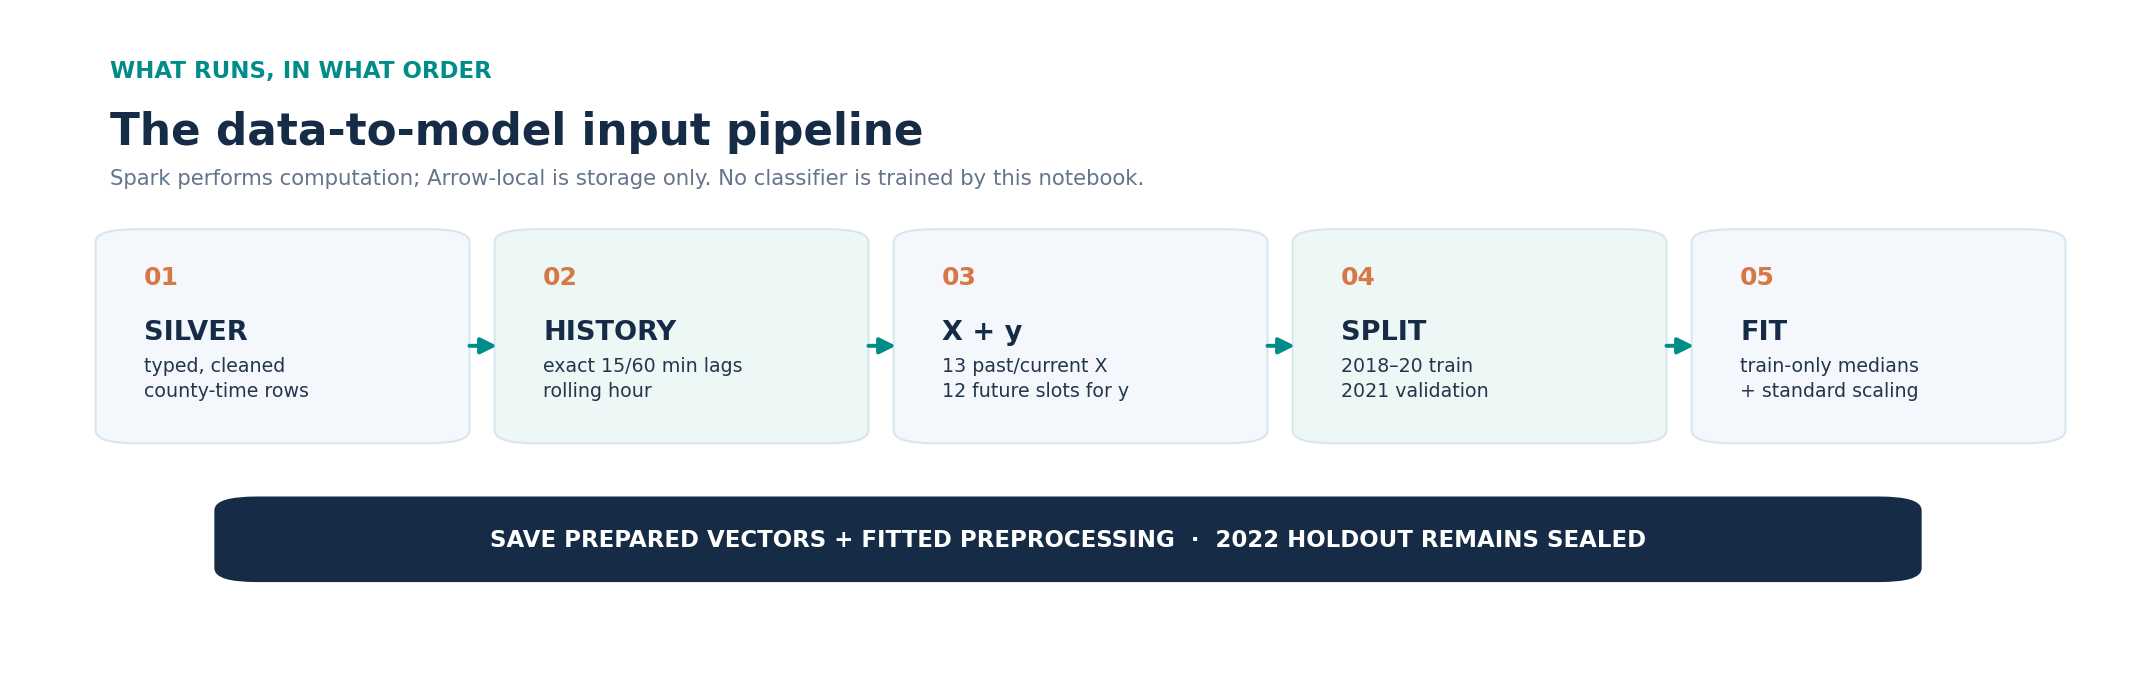

*Conceptual Spark pipeline; saved preprocessing is fitted only on training years.*

<a id="task2-features"></a>
## 01 Feature Engineering
### Identify Features
Source identifiers support temporal grouping and audit joins, not numeric predictors.
Only current/past observations and UTC calendar parts may enter X.

**What / why:** List feature meanings, types, creation rules and exclusions. Only information available at anchor time may enter X.

**How:** The thirteen numeric predictors use current/past values and calendar parts. IDs and all future diagnostics remain metadata; numeric-only X needs no categorical encoder.

**Implementation:** `pipeline.PREDICTORS; reports/FEATURE_DEFINITIONS.md`.

### Before feature generation — leakage and data-type contract

- **Raw source features:** `fips_code`, `county`, `state`, `customers_out`, `run_start_time`. The county name, FIPS and raw timestamp are available for grouping, time ordering and audit, but are deliberately **not** encoded as predictors.
- **Output X:** an ordered list of 13 numeric measurements and indicators computed using observations available at the anchor time.
- **Outcome y:** `candidate_y`, computed **only from future data** and kept outside X. Fully observed positives and negatives both need 12 exact future 15-minute samples; no forward-fill of missing measurements.
- **Removed/unused:** no reliable approved county-customer denominator, so a population-normalized ratio is not manufactured; `future_max`, `future_slots`, `escalation_threshold`, `label_complete`, and other audit columns cannot be predictors.
- **Encoding:** none required because all 13 selected X columns are numeric. If geography later enters a model, encoding must be trained only inside each CV fold.
- **Why StandardScaler rather than MinMax?** StandardScaler supports regularized Logistic Regression by centering variables and expressing them in standard-deviation units. It is **not** inherently outlier-robust or necessarily more accurate than MinMax; tree models do not require scaling. Validation alone establishes which scheme works best.

In [2]:
import pandas as pd
feature_review = [
    ('fips_code','string ID','excluded from X; retained for grouping','Magnitude has no meaning; avoid county memorization'),
    ('county, state','categorical labels','excluded from X; retained for EDA','No encoding needed for selected numeric-only X'),
    ('run_start_time -> timestamp','UTC time','parsed; excluded from X','Ordering and audit key, not a magnitude predictor'),
    ('customers_out -> customers_out_t','integer count','renamed and selected','Observed at anchor t'),
    ('lag_15m','numeric','created and selected','Same county exactly t-15m; missing otherwise'),
    ('lag_60m','numeric','created and selected','Same county exactly t-60m; not four previous rows'),
    ('delta_60m','numeric','created and selected','Current minus exact t-60m lag'),
    ('rolling_mean_60m','numeric','created and selected','Observed [t-60m,t] only; includes current'),
    ('rolling_variance_60m','numeric','created and selected','Population variance over observed historical interval'),
    ('history_slots_60m','integer','created and selected','Coverage count out of five expected historical slots'),
    ('hour_utc, weekday_utc, month_utc','integer calendar','created and selected','UTC extraction; weekday Spark Sunday=1'),
    ('lag_15m_missing, lag_60m_missing, delta_60m_missing','binary indicators','created and selected','Record predictor missingness before training-median imputation'),
    ('future_slots, future_max, candidate_y, escalation_threshold','audit outcomes','excluded from X','Future information is label audit only'),
    ('county_customer_ratio','numeric candidate','not created','No approved time-valid customer denominator available'),
]
display(pd.DataFrame(feature_review,columns=['feature','type','disposition','reason']))

feature  \
0                                                     fips_code   
1                                                 county, state   
2                                   run_start_time -> timestamp   
3                              customers_out -> customers_out_t   
4                                                       lag_15m   
5                                                       lag_60m   
6                                                     delta_60m   
7                                              rolling_mean_60m   
8                                          rolling_variance_60m   
9                                             history_slots_60m   
10                             hour_utc, weekday_utc, month_utc   
11          lag_15m_missing, lag_60m_missing, delta_60m_missing   
12  future_slots, future_max, candidate_y, escalation_threshold   
13                                        county_customer_ratio   

                  type                             disposition  \
0            string ID  excluded from X; retained for grouping   
1   categorical labels       excluded from X; retained for EDA   
2             UTC time                 parsed; excluded from X   
3        integer count                    renamed and selected   
4              numeric                    created and selected   
5              numeric                    created and selected   
6              numeric                    created and selected   
7              numeric                    created and selected   
8              numeric                    created and selected   
9              integer                    created and selected   
10    integer calendar                    created and selected   
11   binary indicators                    created and selected   
12      audit outcomes                         excluded from X   
13   numeric candidate                             not created   

                                                            reason  
0              Magnitude has no meaning; avoid county memorization  
1                   No encoding needed for selected numeric-only X  
2                Ordering and audit key, not a magnitude predictor  
3                                             Observed at anchor t  
4                     Same county exactly t-15m; missing otherwise  
5                Same county exactly t-60m; not four previous rows  
6                                    Current minus exact t-60m lag  
7                        Observed [t-60m,t] only; includes current  
8            Population variance over observed historical interval  
9             Coverage count out of five expected historical slots  
10                          UTC extraction; weekday Spark Sunday=1  
11  Record predictor missingness before training-median imputation  
12                          Future information is label audit only  
13           No approved time-valid customer denominator available

### The exact thirteen positions in X

**What/why:** show the complete ordered contract. **How:** match the definition table to the implemented predictor allowlist plus the three missing flags. **Where:** pipeline.PREDICTORS and reports/FEATURE_DEFINITIONS.md.

In [3]:
feature_specs=[
('customers_out_t','integer count','Reported count at t','Known current severity'),
('lag_15m','numeric, nullable','Same county at exactly t−15m','Recent state'),
('lag_60m','numeric, nullable','Same county at exactly t−60m','One-hour reference'),
('delta_60m','numeric, nullable','customers_out_t − lag_60m','Observed one-hour change'),
('rolling_mean_60m','numeric','Mean of observed [t−60m,t]','Recent severity level'),
('rolling_variance_60m','numeric','Population variance in observed [t−60m,t]','Recent variation'),
('history_slots_60m','integer, 1–5','Count observed [t−60m,t] slots','Expose incomplete history'),
('hour_utc','integer, 0–23','UTC hour of anchor','Time-of-day baseline'),
('weekday_utc','integer, 1–7','Spark Sunday=1 … Saturday=7','Weekly baseline'),
('month_utc','integer, 1–12','UTC calendar month','Seasonal baseline'),
('lag_15m_missing','binary','1 when exact 15m lag is absent','Preserve missingness'),
('lag_60m_missing','binary','1 when exact 60m lag is absent','Preserve missingness'),
('delta_60m_missing','binary','1 when delta is absent','Approved redundant baseline flag')]
display(pd.DataFrame(feature_specs,columns=['X feature in vector order','type','calculation','justification']))
assert [row[0] for row in feature_specs]==PREDICTORS+[c+'_missing' for c in ['lag_15m','lag_60m','delta_60m']]
display(Markdown('**Exclusions:** FIPS/county/state/time identify or order observations but do not enter X. Future maxima/slots, threshold and y are outcome diagnostics. No external customer denominator exists, so no unverified customer ratio was invented. The 60m-lag and delta missing flags are redundant by definition; both remain unchanged as approved.'))

X feature in vector order               type  \
0            customers_out_t      integer count   
1                    lag_15m  numeric, nullable   
2                    lag_60m  numeric, nullable   
3                  delta_60m  numeric, nullable   
4           rolling_mean_60m            numeric   
5       rolling_variance_60m            numeric   
6          history_slots_60m       integer, 1–5   
7                   hour_utc      integer, 0–23   
8                weekday_utc       integer, 1–7   
9                  month_utc      integer, 1–12   
10           lag_15m_missing             binary   
11           lag_60m_missing             binary   
12         delta_60m_missing             binary   

                                  calculation  \
0                         Reported count at t   
1                Same county at exactly t−15m   
2                Same county at exactly t−60m   
3                   customers_out_t − lag_60m   
4                  Mean of observed [t−60m,t]   
5   Population variance in observed [t−60m,t]   
6              Count observed [t−60m,t] slots   
7                          UTC hour of anchor   
8                 Spark Sunday=1 … Saturday=7   
9                          UTC calendar month   
10             1 when exact 15m lag is absent   
11             1 when exact 60m lag is absent   
12                     1 when delta is absent   

                       justification  
0             Known current severity  
1                       Recent state  
2                 One-hour reference  
3           Observed one-hour change  
4              Recent severity level  
5                   Recent variation  
6          Expose incomplete history  
7               Time-of-day baseline  
8                    Weekly baseline  
9                  Seasonal baseline  
10              Preserve missingness  
11              Preserve missingness  
12  Approved redundant baseline flag

**Exclusions:** FIPS/county/state/time identify or order observations but do not enter X. Future maxima/slots, threshold and y are outcome diagnostics. No external customer denominator exists, so no unverified customer ratio was invented. The 60m-lag and delta missing flags are redundant by definition; both remain unchanged as approved.

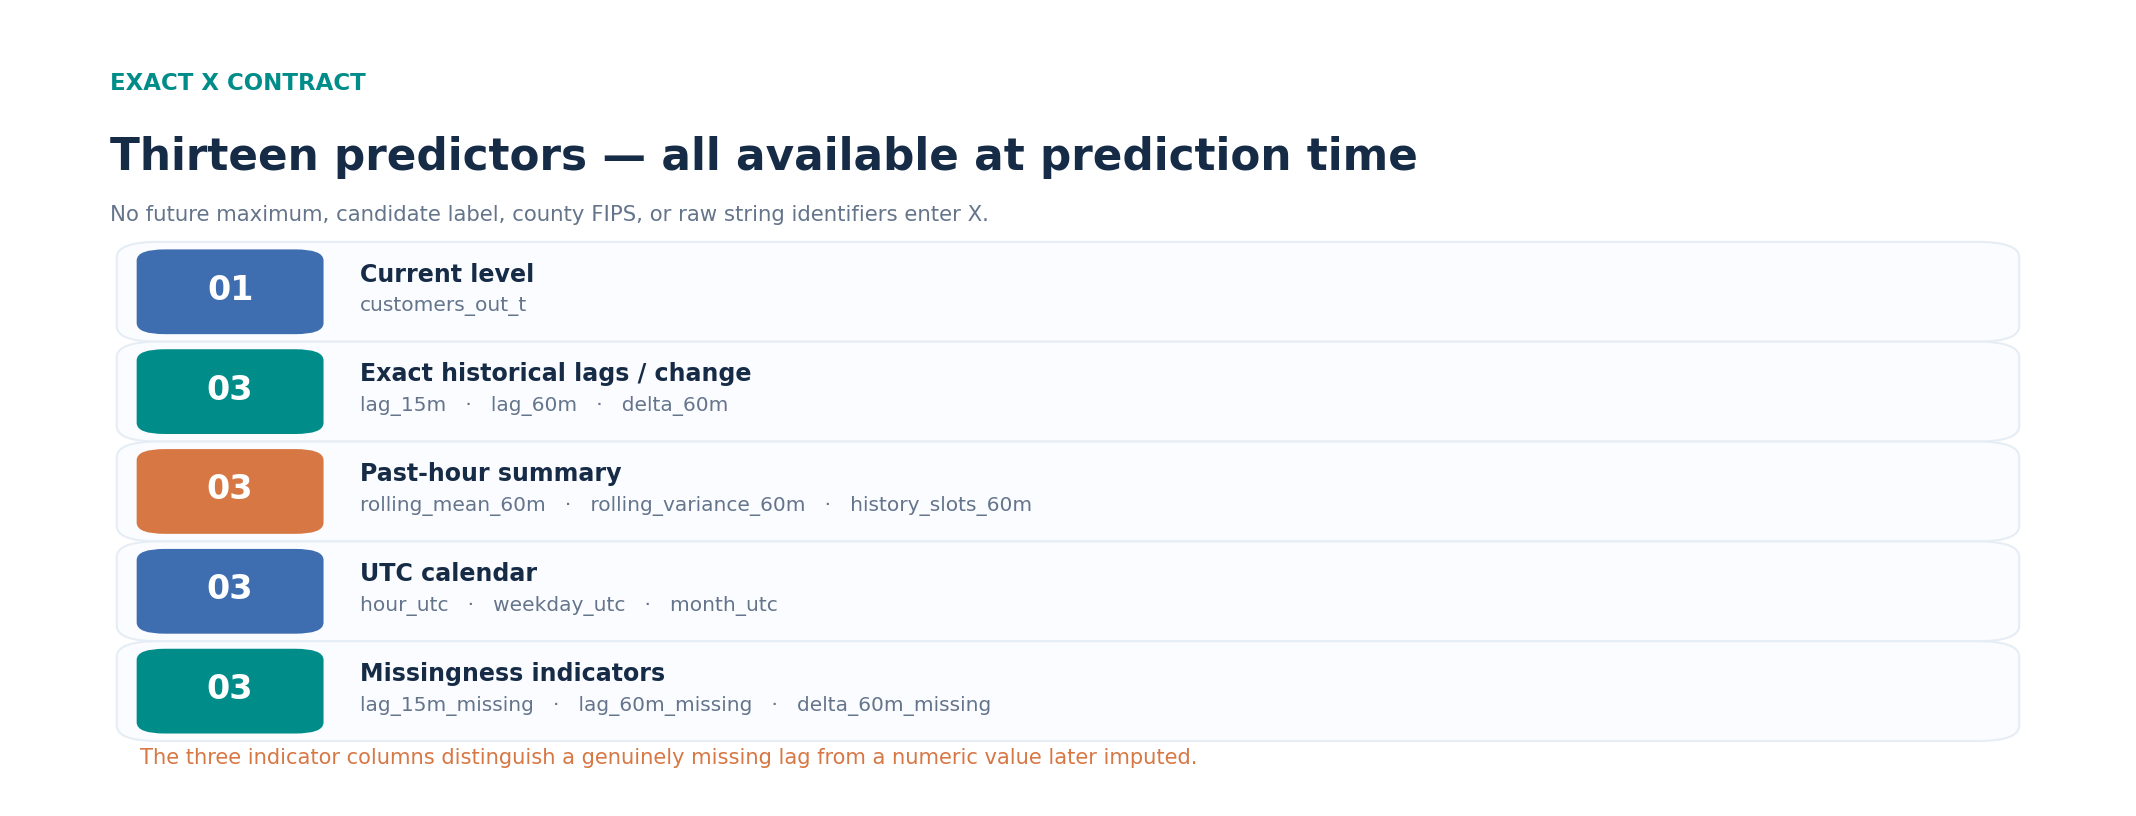

*The 13-position X schema as implemented; y and future outcomes are excluded.*

### Create Features
Recompute exact-timestamp lags and timestamp-based lookbacks from Silver using reusable code.
Count sparse history rather than pretending a complete history exists. Extraction: UTC parts;
generation: lags/deltas/rolling statistics; selection: explicit candidate list, no target-based search.

**What / why:** Build the actual past-only Spark feature table. Exact temporal features preserve meaning when reporting is sparse.

**How:** A rangeBetween(−3600,0) window includes observed points in the past hour; shifted-epoch left joins retrieve exact 15/60-minute lags. Missing matches remain null.

**Implementation:** `src/gridrescue/pipeline.py: features`.

In [4]:
# Call the shared Spark feature builder on clean unique county-time observations.
recomputed = features(silver).cache()
show_table(recomputed.select('fips_code','timestamp',*PREDICTORS).orderBy('fips_code','timestamp'),6)
print('Rows before / after feature generation:',silver.count(),recomputed.count())
assert recomputed.count()==silver.count()
display(Code(inspect.getsource(features),language='python'))
print('Configured shuffle partitions:',spark.conf.get('spark.sql.shuffle.partitions'),'Actual feature partitions:',recomputed.rdd.getNumPartitions())

*Scope: Prefix: 400,000 raw rows, 2018–2021; up to 6 displayed rows.*

fips_code            timestamp  customers_out_t  lag_15m  lag_60m  \
0     01001  2018-01-01 01:00:00                1      NaN      NaN   
1     01001  2018-01-01 01:15:00                1    1.000      NaN   
2     01001  2018-01-01 01:30:00                1    1.000      NaN   
3     01001  2018-01-01 01:45:00                5    1.000      NaN   
4     01001  2018-01-01 02:00:00                5    5.000    1.000   
5     01001  2018-01-01 02:15:00                5    5.000    1.000   

   delta_60m  rolling_mean_60m  rolling_variance_60m  history_slots_60m  \
0        NaN             1.000                 0.000                  1   
1        NaN             1.000                 0.000                  2   
2        NaN             1.000                 0.000                  3   
3        NaN             2.000                 3.000                  4   
4      4.000             2.600                 3.840                  5   
5      4.000             3.400                 3.840                  5   

   hour_utc  weekday_utc  month_utc  
0         1            2          1  
1         1            2          1  
2         1            2          1  
3         1            2          1  
4         2            2          1  
5         2            2          1

Rows before / after feature generation: 333631 333631


def features(silver):
    """Return clean anchors with exact lags, past-hour summaries and UTC calendar fields."""
    base=(silver.withColumn('epoch',F.unix_timestamp('timestamp'))
          .withColumnRenamed('customers_out','customers_out_t'))
    # The range is in seconds because epoch, the ordering column, is in seconds.
    w=Window.partitionBy('fips_code').orderBy('epoch').rangeBetween(-3600,0)
    out=(base.withColumn('rolling_mean_60m',F.avg('customers_out_t').over(w))
         .withColumn('rolling_variance_60m',F.var_pop('customers_out_t').over(w))
         .withColumn('history_slots_60m',F.count('*').over(w)))
    for minutes in [15,60]:
        # Shift each historical lookup key forward to match its future anchor exactly.
        history=base.select('fips_code',(F.col('epoch')+minutes*60).alias('epoch'),F.col('customers_out_t').alias(f'lag_{minutes}m'))
        out=out.join(history,['fips_code','epoch'],'left')
    return (out.withColumn('delta_60m',F.col('customers_out_t')-F.col('lag_60m'))
            .withColumn('hour_utc',F.hour('timestamp')).withColumn('weekday_utc',F.dayofweek('timestamp'))
            .withColumn('month_utc',F.month('timestamp')))

Configured shuffle partitions: 4 Actual feature partitions: 4


### Review Changes
The feature table above is the complete disposition record. Verify an exact lag by a timestamp
equality join; absence remains null. Rolling windows never extend beyond anchor t.

**What / why:** Independently verify the exact one-hour lag. Four previous rows can span more than an hour when observations are absent.

**How:** A same-county timestamp equality left join must match the stored lag using null-safe equality. count triggers verification.

**Implementation:** `Spark join and eqNullSafe below`.

In [5]:
# Join the anchor to the same county exactly one hour earlier and compare the results.
lag_check = (recomputed.alias('a').join(silver.alias('h'),
     (F.col('a.fips_code')==F.col('h.fips_code')) &
     (F.col('h.timestamp')==F.col('a.timestamp')-F.expr('INTERVAL 60 MINUTES')),'left')
     .select(F.col('a.lag_60m').alias('computed'),F.col('h.customers_out').alias('expected')))
assert lag_check.filter(~F.col('computed').eqNullSafe(F.col('expected'))).count()==0
print('Exact 60-minute lag checked against independent timestamp equality join.')

Exact 60-minute lag checked against independent timestamp equality join.


#### Understanding the code — exact-time joins and windows

`F.col()` refers to a column in Spark expressions. `withColumn()` returns a new DataFrame with the given column added or replaced. A left `join()` on county and exact epoch keeps the anchor even if the lookup fails. `Window.partitionBy()` isolates counties, `orderBy()` sets epoch order, and `over()` applies a calculation in the specified frame. **TA question:** Why avoid `lag(4)` for a one-hour feature? **Answer:** Four previous rows may extend further back when slots are missing.

### Manually check real county history

**What/why:** verify exact lag joins and past-only rolling statistics using actual Los Angeles reports. **How:** display at most five rows from a complete one-hour history, calculate values independently, then show real missing-lag rows. **Where:** pipeline.features and persisted county Silver/Gold.

In [6]:
import math
from datetime import datetime,timedelta
county_locations=scope_paths(ROOT,'county','arrow-local' if MODE=='arrow-local' else 'native')
if MODE=='memory':
    county_silver,_,_=clean(read_source(spark,sorted((ROOT/'data/county_coverage').glob('*.csv'))))
    county_gold=features(county_silver)
else:
    county_silver=read_frame(spark,county_locations['silver'])
    county_gold=read_frame(spark,county_locations['gold'])
anchor=(county_gold.filter((F.col('fips_code')=='06037') & (F.year('timestamp')==2020) &
         (F.month('timestamp')==7) & (F.col('history_slots_60m')==5)).orderBy('timestamp')
         .select('fips_code',F.date_format('timestamp','yyyy-MM-dd HH:mm:ss').alias('anchor_utc'),*PREDICTORS).first())
assert anchor is not None,'No qualified real July anchor; do not fabricate a manual example'
anchor_time=F.to_timestamp(F.lit(anchor.anchor_utc))
# Select the same county in the inclusive past hour, then sort its known observations.
history=(county_silver.filter((F.col('fips_code')==anchor.fips_code)&
          F.col('timestamp').between(anchor_time-F.expr('INTERVAL 60 MINUTES'),anchor_time))
          .select(F.date_format('timestamp','yyyy-MM-dd HH:mm:ss').alias('timestamp_utc'),'customers_out').orderBy('timestamp_utc'))
history_rows=history.collect()  # At most five actual quarter-hour observations.
display(pd.DataFrame([row.asDict() for row in history_rows]))
lookup={row.timestamp_utc:row.customers_out for row in history_rows}
when=datetime.fromisoformat(anchor.anchor_utc)
lag15=lookup.get(str(when-timedelta(minutes=15))); lag60=lookup.get(str(when-timedelta(minutes=60)))
values=[row.customers_out for row in history_rows]
mean=math.fsum(values)/len(values); variance=math.fsum((v-mean)**2 for v in values)/len(values)
checks=[('current',lookup[str(when)],anchor.customers_out_t),('lag_15m',lag15,anchor.lag_15m),
        ('lag_60m',lag60,anchor.lag_60m),('delta_60m',lookup[str(when)]-lag60,anchor.delta_60m),
        ('rolling_mean_60m',mean,anchor.rolling_mean_60m),('rolling_variance_60m',variance,anchor.rolling_variance_60m),
        ('history_slots_60m',len(values),anchor.history_slots_60m)]
display(pd.DataFrame(checks,columns=['check','manual result','Spark feature']))
# Compare the manual numbers with Spark outputs using a small rounding tolerance.
assert all(math.isclose(float(manual),float(actual),rel_tol=1e-10,abs_tol=1e-6) for _,manual,actual in checks)
display(Markdown(f"**Manual verification:** Los Angeles at {anchor.anchor_utc} UTC uses exactly the five displayed historical observations. Mean={mean:,.3f}, population variance={variance:,.3f}. The current observation is included; no future value is used."))
missing_example=county_gold.filter('lag_15m IS NULL OR lag_60m IS NULL').orderBy('timestamp','fips_code')
for name in ['lag_15m','lag_60m','delta_60m']:
    missing_example=missing_example.withColumn(name+'_missing',F.col(name).isNull().cast('double'))
show_table(missing_example.select('fips_code','timestamp','customers_out_t','lag_15m','lag_60m','delta_60m',
           'lag_15m_missing','lag_60m_missing','delta_60m_missing'),3,scope='Three counties, all development dates (2018–2021)')
display(Markdown('**Missing-lag interpretation:** null means that exact historical timestamp is absent. A flag records the gap. Later median imputation fills only a predictor position; it does not create an outage report or change y.'))

timestamp_utc  customers_out
0  2020-06-30 23:00:00           1644
1  2020-06-30 23:15:00           1533
2  2020-06-30 23:30:00           3115
3  2020-06-30 23:45:00           2529
4  2020-07-01 00:00:00           1216

check  manual result  Spark feature
0               current      1,216.000      1,216.000
1               lag_15m      2,529.000      2,529.000
2               lag_60m      1,644.000      1,644.000
3             delta_60m       -428.000       -428.000
4      rolling_mean_60m      2,007.400      2,007.400
5  rolling_variance_60m    496,454.640    496,454.640
6     history_slots_60m          5.000          5.000

**Manual verification:** Los Angeles at 2020-07-01 00:00:00 UTC uses exactly the five displayed historical observations. Mean=2,007.400, population variance=496,454.640. The current observation is included; no future value is used.

*Scope: Three counties, all development dates (2018–2021); up to 3 displayed rows.*

fips_code            timestamp  customers_out_t  lag_15m  lag_60m  \
0     06037  2018-01-01 00:00:00                8      NaN      NaN   
1     12086  2018-01-01 00:00:00              658      NaN      NaN   
2     48201  2018-01-01 00:00:00               18      NaN      NaN   

   delta_60m  lag_15m_missing  lag_60m_missing  delta_60m_missing  
0        NaN            1.000            1.000              1.000  
1        NaN            1.000            1.000              1.000  
2        NaN            1.000            1.000              1.000

**Missing-lag interpretation:** null means that exact historical timestamp is absent. A flag records the gap. Later median imputation fills only a predictor position; it does not create an outage report or change y.

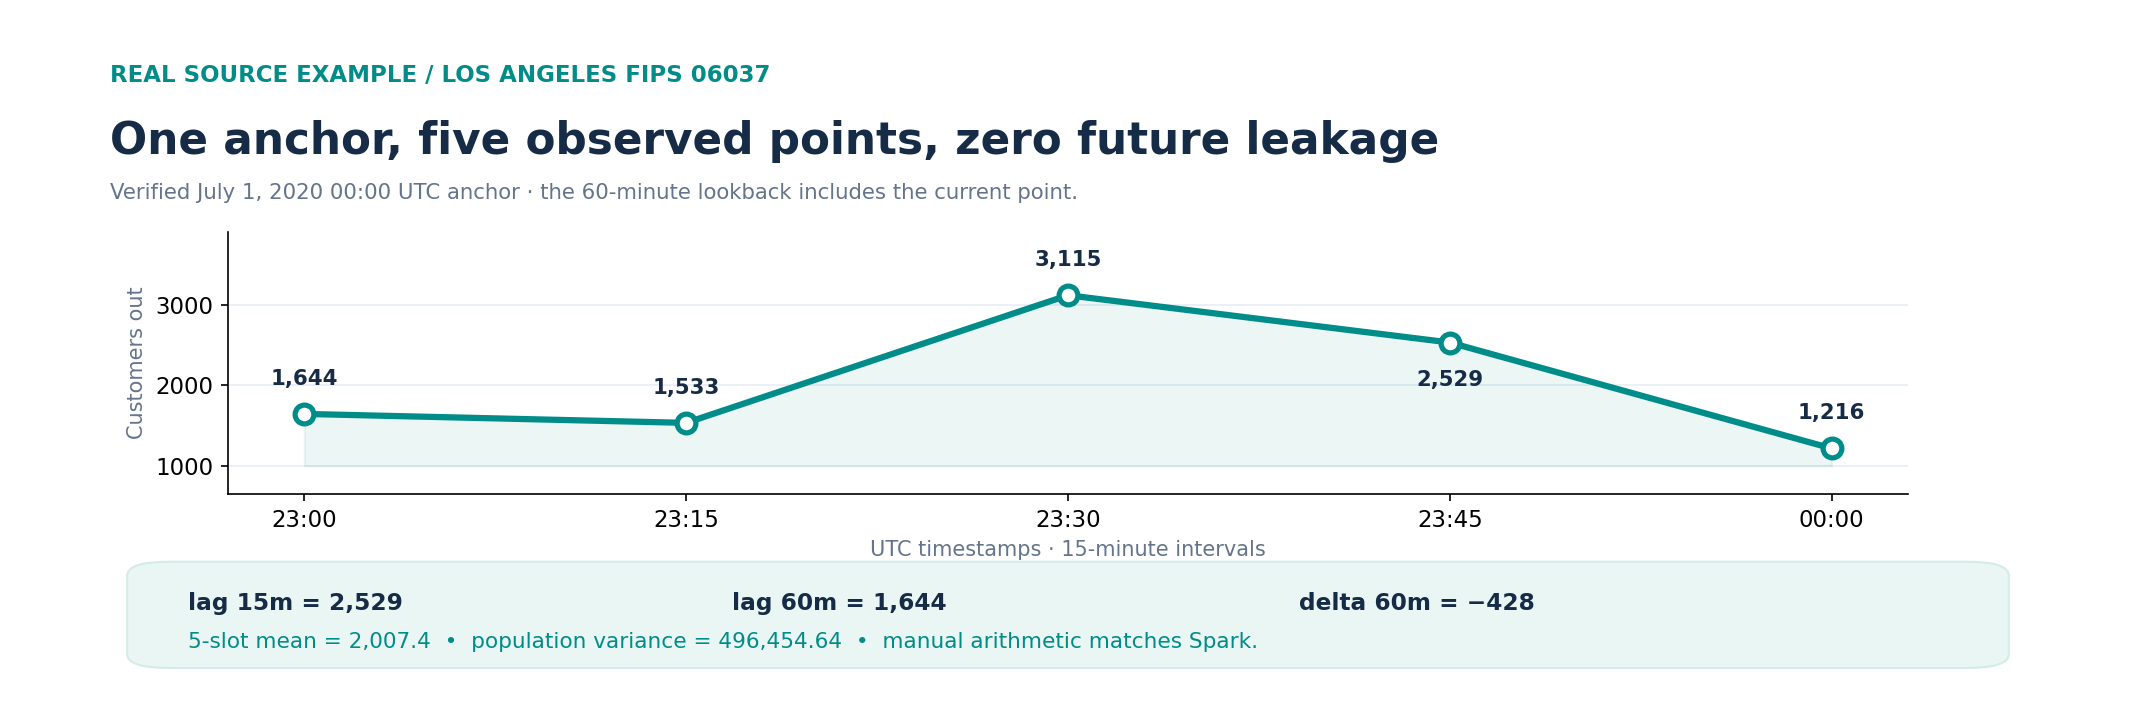

*Five real observations from the executed Los Angeles example, reproduced as a visual timeline.*

<a id="task2-splitting"></a>
## 02 Data Splitting
### Define Inputs — X and provisional y
X contains selected current/past features and calendar parts. Candidate y=1 if the future maximum
reaches current count + max(200, 50% of current count) within (t,t+3h]. An anchor must have a
positive observed current outage and all twelve exact quarter-hour future slots for either class.
Incomplete windows remain unlabeled, even if an observed future value crosses the threshold.
This conservative audit rule avoids asymmetric completeness selection but selects persistent outages.
The user conditionally approved this unchanged target for the fixed three-county university experiment.

**What / why:** Define X and audit the approved target y. Outcome eligibility is separate from feature missingness.

**How:** The future window is (t,t+3h], requiring twelve unique grid-aligned slots and positive current count. Threshold is current+max(200,0.5×current). Future columns never enter X.

**Implementation:** `pipeline.audit_labels; reports/target_approval.json`.

In [7]:
# Compute future-window eligibility and y using the shared source function.
candidate = audit_labels(recomputed).cache()
for c in ['lag_15m','lag_60m','delta_60m']:
    # Compute future-window eligibility and y using the shared source function.
    candidate = candidate.withColumn(c+'_missing',F.col(c).isNull().cast('double'))
X_COLUMNS = PREDICTORS + [c+'_missing' for c in ['lag_15m','lag_60m','delta_60m']]
print('X:',X_COLUMNS)
print('Experimental y: candidate_y; three-county target conditionally approved; never imputed.')
# Fail if a future-derived audit field appears in the feature list.
assert not set(X_COLUMNS) & {'candidate_y','future_slots','future_max','escalation_threshold'}
candidate.groupBy(F.year('timestamp').alias('year'),'split','label_complete','candidate_y').count().orderBy('year','candidate_y').show(40)

X: ['customers_out_t', 'lag_15m', 'lag_60m', 'delta_60m', 'rolling_mean_60m', 'rolling_variance_60m', 'history_slots_60m', 'hour_utc', 'weekday_utc', 'month_utc', 'lag_15m_missing', 'lag_60m_missing', 'delta_60m_missing']
Experimental y: candidate_y; three-county target conditionally approved; never imputed.


+----+----------+--------------+-----------+-----+
|year|     split|label_complete|candidate_y|count|
+----+----------+--------------+-----------+-----+
|2018|     train|         false|       NULL|55774|
|2018|     train|          true|          0|32379|
|2018|     train|          true|          1| 3376|
|2019|     train|         false|       NULL|36476|
|2019|     train|          true|          0|40903|
|2019|     train|          true|          1| 3592|
|2020|     train|         false|       NULL|32978|
|2020|     train|          true|          0|28301|
|2020|     train|          true|          1| 1234|
|2021|validation|         false|       NULL|45017|
|2021|validation|          true|          0|49059|
|2021|validation|          true|          1| 4542|
+----+----------+--------------+-----------+-----+



#### Understanding the code — label construction

The forward window runs from t+15 minutes through t+180 minutes. Clean keys are unique and quarter-hour aligned, so a count of 12 means every expected slot exists. **TA question:** Is an incomplete window with an early large rise positive? **Answer:** It remains unlabeled because both classes use the same completeness rule.

### Candidate Label Feasibility — Manually Inspectable Examples
Inspect positive, negative, incomplete and boundary anchors and their full available trajectories.
If a category is absent in this actual prefix, report absence rather than inventing an example.
Prefix boundaries are selection artifacts; no approved final-test balance is inferred.

**What / why:** Inspect actual positive, negative, incomplete and boundary traces. See why unknown future observations cannot safely become negatives.

**How:** Choose bounded examples, list expected quarter-hours and compare actual reports. If a category is absent, say so; do not fabricate it.

**Implementation:** `pipeline.audit_labels; reports/real_trace_checks.json`.

In [8]:
# Use separate examples for positives, negatives and incomplete outcomes.
for name,predicate in [('positive','candidate_y=1'),('negative','candidate_y=0'),
                       ('incomplete','NOT label_complete'),('split_boundary',"split='purged'")]:
    example=(candidate.filter(predicate).orderBy('timestamp','fips_code')
             .withColumn('timestamp',F.date_format('timestamp','yyyy-MM-dd HH:mm:ss')).first())
    print('CATEGORY:',name)
    if example is None:
        print('No observed example in this selected subset; not fabricated.')
        continue
    print({k:example[k] for k in ['fips_code','timestamp','customers_out_t','escalation_threshold','future_slots','future_max','candidate_y','split']})
    from datetime import datetime, timedelta
    anchor=datetime.fromisoformat(example['timestamp'])
    anchor_spark=F.to_timestamp(F.lit(example['timestamp']))
    trajectory=silver.filter((F.col('fips_code')==example['fips_code']) &
               F.col('timestamp').between(anchor_spark,anchor_spark+F.expr('INTERVAL 3 HOURS')))
    show_table(trajectory.select('timestamp','customers_out').orderBy('timestamp'),13)
    actual_times={datetime.fromisoformat(r[0]) for r in trajectory.select(F.date_format('timestamp','yyyy-MM-dd HH:mm:ss')).collect()}
    expected_times=[anchor+timedelta(minutes=15*i) for i in range(1,13)]
    print('Missing expected future slots:',[str(t) for t in expected_times if t not in actual_times])
    observed_with_endpoints=sorted(actual_times | {anchor,anchor+timedelta(hours=3)})
    print('Largest span between observed times/endpoints in minutes:',max(
        ((b-a).total_seconds()/60 for a,b in zip(observed_with_endpoints,observed_with_endpoints[1:])),default=0))
print('Read reports/LABEL_FEASIBILITY.md for selection bias and scientific blockers.')

CATEGORY: positive
{'fips_code': '01073', 'timestamp': '2018-01-01 00:00:00', 'customers_out_t': 6, 'escalation_threshold': 206.0, 'future_slots': 12, 'future_max': 242, 'candidate_y': 1, 'split': 'train'}


*Scope: Prefix: 400,000 raw rows, 2018–2021; up to 13 displayed rows.*

timestamp  customers_out
0   2018-01-01 00:00:00              6
1   2018-01-01 00:15:00              6
2   2018-01-01 00:30:00              6
3   2018-01-01 00:45:00             11
4   2018-01-01 01:00:00             11
5   2018-01-01 01:15:00              6
6   2018-01-01 01:30:00              4
7   2018-01-01 01:45:00            242
8   2018-01-01 02:00:00            147
9   2018-01-01 02:15:00            147
10  2018-01-01 02:30:00            149
11  2018-01-01 02:45:00            240
12  2018-01-01 03:00:00             46

Missing expected future slots: []
Largest span between observed times/endpoints in minutes: 15.0


CATEGORY: negative
{'fips_code': '01117', 'timestamp': '2018-01-01 00:00:00', 'customers_out_t': 2, 'escalation_threshold': 202.0, 'future_slots': 12, 'future_max': 88, 'candidate_y': 0, 'split': 'train'}


*Scope: Prefix: 400,000 raw rows, 2018–2021; up to 13 displayed rows.*

... (2 outputs left out)

CATEGORY: incomplete
{'fips_code': '01015', 'timestamp': '2018-01-01 00:00:00', 'customers_out_t': 1, 'escalation_threshold': 201.0, 'future_slots': 0, 'future_max': None, 'candidate_y': None, 'split': 'train'}


*Scope: Prefix: 400,000 raw rows, 2018–2021; up to 13 displayed rows.*

timestamp  customers_out
0  2018-01-01 00:00:00              1

Missing expected future slots: ['2018-01-01 00:15:00', '2018-01-01 00:30:00', '2018-01-01 00:45:00', '2018-01-01 01:00:00', '2018-01-01 01:15:00', '2018-01-01 01:30:00', '2018-01-01 01:45:00', '2018-01-01 02:00:00', '2018-01-01 02:15:00', '2018-01-01 02:30:00', '2018-01-01 02:45:00', '2018-01-01 03:00:00']
Largest span between observed times/endpoints in minutes: 180.0
CATEGORY: split_boundary
No observed example in this selected subset; not fabricated.
Read reports/LABEL_FEASIBILITY.md for selection bias and scientific blockers.


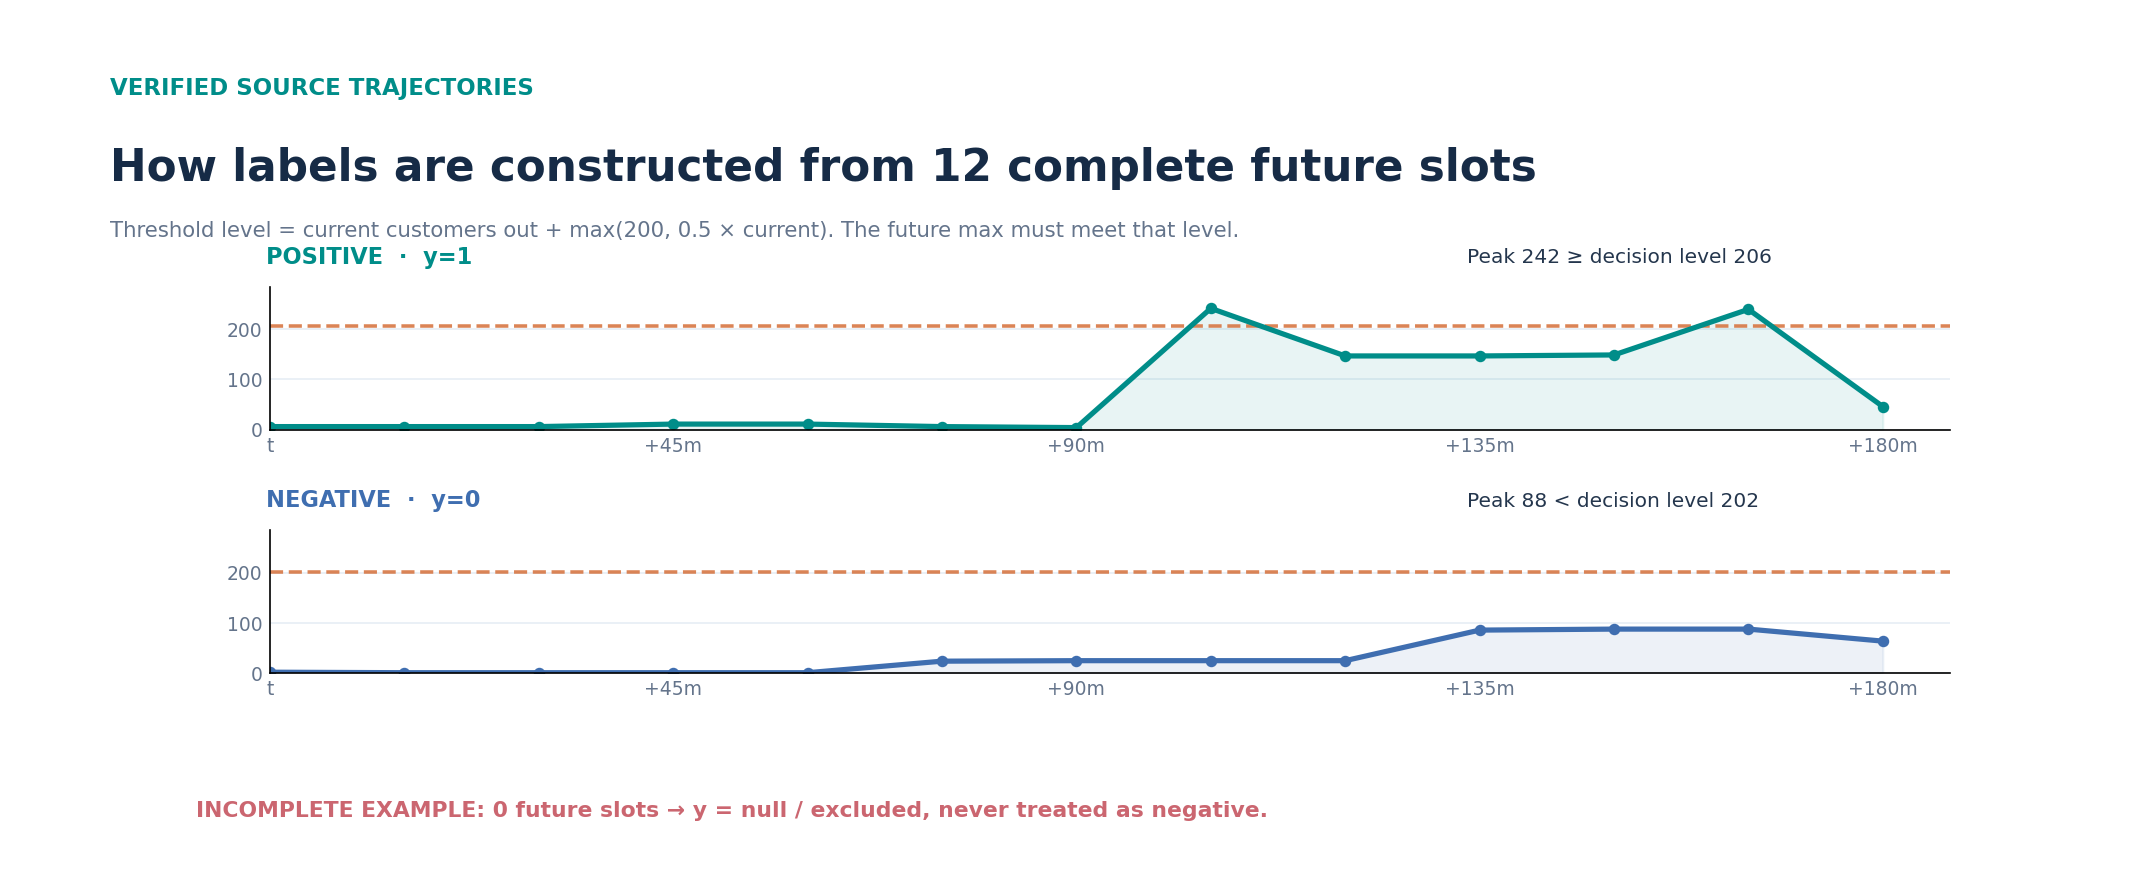

*Both traces are real prefix examples. The incomplete case has no valid class label.*

**What / why:** Measure which observations and counties remain eligible. Complete-case selection can favor persistent, well-reported severe outages.

**How:** Grouped all-versus-eligible severity and coverage expose selection. These are descriptive checks, not training or a change to the cohort.

**Implementation:** `Spark groupBy; reports/target_feasibility.json`.

In [9]:
selection = candidate.groupBy(F.year('timestamp').alias('year'),'state').agg(
    F.count('*').alias('observed_anchors'),
    F.sum(F.col('candidate_y').isNotNull().cast('long')).alias('eligible_anchors'),
    F.avg('customers_out_t').alias('mean_current_all'),
    F.avg(F.when(F.col('candidate_y').isNotNull(),F.col('customers_out_t'))).alias('mean_current_eligible'))
selection.withColumn('eligibility_fraction',F.col('eligible_anchors')/F.col('observed_anchors')).orderBy('year',F.desc('observed_anchors')).show(30,truncate=False)
candidate.groupBy('fips_code',F.year('timestamp').alias('year')).agg(
    F.count('*').alias('anchors'),F.sum(F.col('candidate_y').isNotNull().cast('long')).alias('eligible')).orderBy('eligible','fips_code').show(15)
print('Compare eligibility fractions and all-versus-eligible severity to assess selection; sparse counties and prefix edges can be excluded disproportionately.')

+----+--------------+----------------+----------------+------------------+---------------------+--------------------+
|year|state         |observed_anchors|eligible_anchors|mean_current_all  |mean_current_eligible|eligibility_fraction|
+----+--------------+----------------+----------------+------------------+---------------------+--------------------+
|2018|Texas         |10713           |4725            |127.9071221879959 |218.06560846560848   |0.44105292635116217 |
|2018|Virginia      |5256            |2191            |66.34208523592085 |81.66408032861708    |0.4168569254185693  |
|2018|Georgia       |5070            |1861            |51.230571992110455|72.368081676518      |0.3670611439842209  |
|2018|Florida       |4859            |2198            |85.57583864992797 |123.13057324840764   |0.45235645194484464 |
|2018|North Carolina|4858            |1689            |105.02593659942363|198.92184724689164   |0.3476739398929601  |
|2018|Louisiana     |4677            |2189            |1

+---------+----+-------+--------+
|fips_code|year|anchors|eligible|
+---------+----+-------+--------+
|    01001|2021|     28|       0|
|    01001|2019|     17|       0|
|    01003|2020|     19|       0|
|    01005|2020|     11|       0|
|    01005|2019|      3|       0|
|    01007|2020|     17|       0|
|    01007|2018|     34|       0|
|    01011|2020|     29|       0|
|    01011|2021|     26|       0|
|    01011|2018|      6|       0|
|    01013|2020|     17|       0|
|    01013|2018|     35|       0|
|    01013|2021|     13|       0|
|    01015|2020|     38|       0|
|    01017|2021|      9|       0|
+---------+----+-------+--------+
only showing top 15 rows

Compare eligibility fractions and all-versus-eligible severity to assess selection; sparse counties and prefix edges can be excluded disproportionately.


### Nested eligibility stages and exclusions

**What/why:** count every outcome eligibility gate in both scopes. **How:** one compact Spark aggregation per scope; no future null is recoded. **Where:** pipeline.audit_labels.

In [10]:
stages=[]
for scope,frame in [('Prefix',candidate),('Three counties',read_frame(spark,county_locations['label_audit']) if MODE!='memory' else audit_labels(county_gold))]:
    row=frame.agg(F.count('*').alias('clean'),F.sum((F.col('customers_out_t')>0).cast('long')).alias('positive_current'),
        F.sum(((F.col('customers_out_t')>0)&(F.col('future_slots')==12)).cast('long')).alias('complete_future'),
        F.sum((F.col('candidate_y').isNotNull()&F.col('split').isin('train','validation')).cast('long')).alias('eligible'),
        F.sum((F.col('split')=='purged').cast('long')).alias('purged')).first().asDict()
    stages.append({'scope':scope,**row,'excluded_clean_anchors':row['clean']-row['eligible']})
display(pd.DataFrame(stages))
assert all(row['clean']>=row['positive_current']>=row['complete_future']>=row['eligible'] for row in stages)
display(Markdown('**Eligibility interpretation:** each successive column applies an additional rule; these columns are nested stages, not removal categories to add together. Incomplete future windows are excluded from both classes even if a partial trace crosses the threshold. Boundary purges can be zero in real data because source years end before the final three hours; the boundary behavior is tested synthetically.'))

scope   clean  positive_current  complete_future  eligible  \
0          Prefix  333631            333631           163386    163386   
1  Three counties  416940            416940           406240    406240   

   purged  excluded_clean_anchors  
0       0                  170245  
1       0                   10700

**Eligibility interpretation:** each successive column applies an additional rule; these columns are nested stages, not removal categories to add together. Incomplete future windows are excluded from both classes even if a partial trace crosses the threshold. Boundary purges can be zero in real data because source years end before the final three hours; the boundary behavior is tested synthetically.

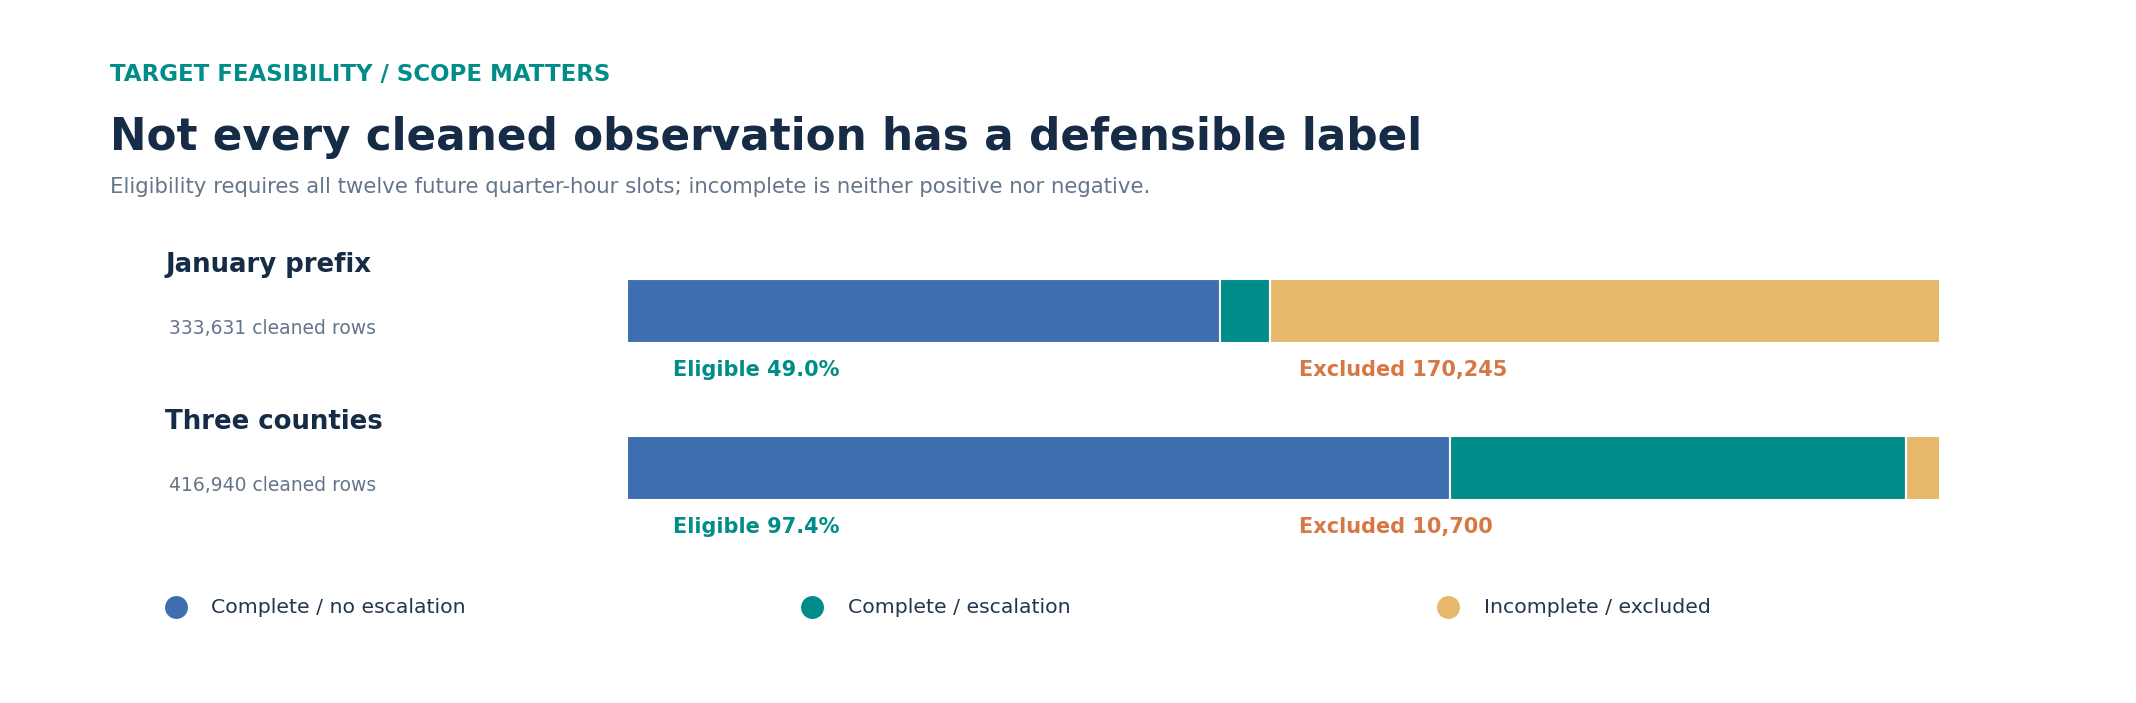

*The same measured eligibility ledger, now shown at the input/target filtering step.*

### Split the Data
Train: 2018-2020; validation: 2021; held-out final test: 2022. Labels whose horizon reaches a
partition boundary (2021, 2022 or end of test) are purged. All 2022 labels, scores and feature choices remain
uninspected during development. A zero test count here means no 2022 rows loaded, not no test data.

**What / why:** Reserve chronological train, validation and sealed test periods. Random row splits would mix adjacent, overlapping windows.

**How:** Filter only labeled development anchors. Assert that every training/validation label horizon stays before the next partition. 2022 remains unmaterialized.

**Implementation:** `pipeline.split_tag and audit_labels split expressions`.

In [11]:
# Filter to labeled train and validation anchors. A missing label is excluded.
prepared = candidate.filter("candidate_y IS NOT NULL AND split IN ('train','validation')")
prepared.groupBy('split').agg(F.count('*').alias('eligible_rows'),F.avg('candidate_y').alias('candidate_positive_prevalence')).show()
# Check the development artifact has no test split.
assert candidate.filter("split='test'").count()==0
# Check no included outcome window ends at or beyond its split boundary.
assert prepared.filter("(split='train' AND timestamp + INTERVAL 3 HOURS >= TIMESTAMP '2021-01-01') OR (split='validation' AND timestamp + INTERVAL 3 HOURS >= TIMESTAMP '2022-01-01')").count()==0
print('Test materialization: deferred; no 2022 predictors or labels loaded in this notebook.')

+----------+-------------+-----------------------------+
|     split|eligible_rows|candidate_positive_prevalence|
+----------+-------------+-----------------------------+
|validation|        53601|          0.08473722505177142|
|     train|       109785|          0.07470965978958874|
+----------+-------------+-----------------------------+



Test materialization: deferred; no 2022 predictors or labels loaded in this notebook.


#### Understanding the code — chronological splitting

Train on 2018–2020, select using 2021, and seal 2022. Comparing `timestamp + INTERVAL 3 HOURS` to the boundary checks where each label can look. **TA question:** What happens to an anchor at 21:00 UTC on December 31, 2020? **Answer:** Its horizon ends exactly at the split boundary, so it is purged.

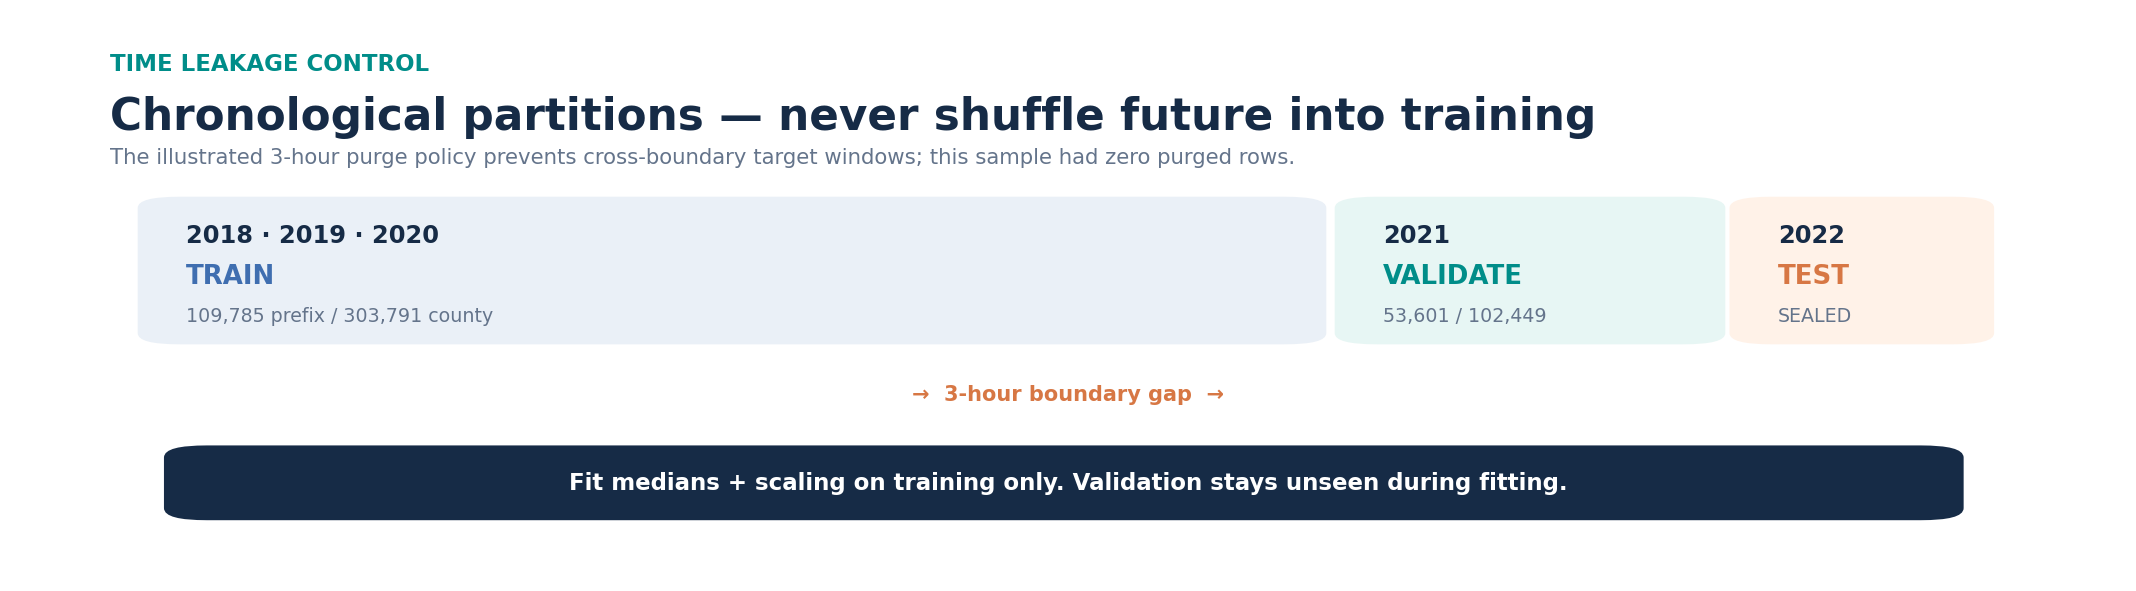

*Year-based partitions with the approved 3-hour purge rule, not a random shuffled split.*

### Avoid Leakage
No forward/centered rolling features. Future measurements live only in candidate audit columns,
not X. Nearby observations are temporally correlated, so random row splitting is inappropriate.
Learned preprocessing is fitted only on eligible training anchors; in Task 3 it must be refitted
separately inside each chronological CV fold. No target-based feature selection has been run.
Adjacent quarter-hour prediction windows can share eleven of twelve future observations;
rows are dependent, not independent outage events. Boundary purges cover the three-hour
horizon. Any later CV requires the same time-aware gap and fold-only preprocessing, but no
CV or classifier fitting is authorized during this notebook review.

**Why refit preprocessing inside each chronological CV fold?** Task 2's saved training fit uses 2018–2020. In a later fold that validates on 2019, only 2018 belongs to that fold's training period. Reusing the Task 2 fit would let 2019 and 2020 influence medians, means and standard deviations before evaluating 2019—even without using y. That leaks validation/future distribution information.

Each fold must therefore start with an unfitted preprocessing-plus-model pipeline, fit learned steps on that fold's earlier training rows, and apply them unchanged to its validation rows. The three-hour purge separately prevents label-horizon overlap across the boundary; it does not solve preprocessing leakage. After choosing a model using development evidence, the final allowed training refit is a separate step. This explanation changes no methodology and runs no CV or classifier.


<a id="task2-preprocessing"></a>
## 03 Data Preprocessing
### Missing Values
Preserve missingness indicators and impute eligible predictor nulls with training medians only.
This creates predictor vectors, not missing source outage observations or labels. An entirely
null training feature is a block requiring a documented decision, not an invented median.
### Categorical Encoding
Selected X is numeric only; state/county/FIPS remain audit metadata. No categorical encoder is
fitted. If categories are selected later, their encoder must be trained inside each training fold.
### Feature Scaling
Preparation uses Spark median Imputer, VectorAssembler and StandardScaler. Standardization
uses training mean/std; it differs from unit-norm normalization. Binary missing flags are assembled
with numeric variables. Trees need not use standardized vectors; no estimator is fitted here.

**What / why:** Load or fit training-only median imputation and standardization. Predictors can be missing even when an outcome is complete; validation must not set training statistics.

**How:** Spark fits Imputer→VectorAssembler→StandardScaler on eligible 2018–2020 rows. Median quantiles use error 0.001; StandardScaler uses corrected sample standard deviation. A constant training feature maps to zero.

**Implementation:** `pipeline.fit_preparation; storage.load_preparation`.

In [12]:
# Load the fitting statistics from disk when using a persisted cohort.
prep_path = BASE / 'preparation'
preparation = fit_preparation(prepared,X_COLUMNS) if MODE=='memory' else load_preparation(prep_path) if prep_path.exists() else None
if preparation is None:
    print('BLOCKED: fitted preparation artifact absent; inspect pipeline runtime log. No fabricated transformed output.')
else:
    print('Fitted stages:',[type(stage).__name__ for stage in preparation.stages])
    print('Persistence:', 'NOT SAVED: in-memory execution' if MODE=='memory' else 'Loaded saved artifact')
    # Display all actual training statistics once in the next worked example.


    # Apply the fitted stages to both partitions without learning new statistics.
    transformed=preparation.transform(prepared)
    # Final vectors are displayed once under Final Data Checks.
    constant=[name for name,std in zip(X_COLUMNS,preparation.stages[-1].std) if std==0]
    display(Markdown('**Training coverage limitation:** zero-variance training predictors: ' + ', '.join(constant) + '. Prefix training is January-only, so its scaler cannot establish seasonal feature feasibility. The separate county feature audit covers longer date ranges.'))
    if MODE=='memory':
        stats={'mode':MODE,'predictors':X_COLUMNS,'training_rows':prepared.filter("split='train'").count(),
               'medians':preparation.stages[0].surrogateDF.first().asDict(),
               'scaler_mean':[float(v) for v in preparation.stages[-1].mean],
               'scaler_std':[float(v) for v in preparation.stages[-1].std],
               'constant_training_predictors':constant,'spark_pipeline_saved':False}
        (ROOT/'reports/preparation_memory.json').write_text(json.dumps(stats,indent=2),encoding='utf-8')

Fitted stages: ['ImputerModel', 'VectorAssembler', 'StandardScalerModel']
Persistence: Loaded saved artifact


**Training coverage limitation:** zero-variance training predictors: month_utc. Prefix training is January-only, so its scaler cannot establish seasonal feature feasibility. The separate county feature audit covers longer date ranges.

### Training statistics and a real before/after example

**What/why:** make fitted imputation and scaling independently checkable. **How:** display the thirteen fitted statistics and transform one eligible row with missing history. **Where:** Spark PipelineModel stages; pipeline.fit_preparation; storage.load_preparation.

In [13]:
assert preparation is not None
# Unpack the fitted stages in the order the Pipeline executes them.
imputer,assembler,scaler=preparation.stages
medians=imputer.surrogateDF.first().asDict()
fitted=pd.DataFrame({'feature':X_COLUMNS,'training median':[medians[c] for c in X_COLUMNS],
                     'mean after imputation':list(scaler.mean),'sample standard deviation':list(scaler.std)})
display(fitted)
small=prepared.filter('lag_15m IS NULL OR lag_60m IS NULL').orderBy('timestamp','fips_code').limit(1)
# Apply the saved transform and pull one bounded example with missing history.
example=preparation.transform(small).select(*X_COLUMNS,*imputer.getOutputCols(),'scaled_features').first()
assert example is not None,'No missing-history eligible example; report rather than invent one'
comparison=[]
for i,name in enumerate(X_COLUMNS):
    raw_value=example[name]; imputed=example[imputer.getOutputCols()[i]]
    # Recalculate (imputed value - train mean) / train sample standard deviation.
    expected=(imputed-scaler.mean[i])/scaler.std[i] if scaler.std[i]!=0 else 0.
    actual=float(example.scaled_features[i])
    assert math.isclose(actual,expected,rel_tol=1e-12,abs_tol=1e-12)
    comparison.append({'feature':name,'raw predictor':raw_value,'imputed predictor':imputed,'scaled predictor':actual})
display(pd.DataFrame(comparison))
display(Markdown('**Read the example:** absent lag/change entries become the displayed training medians; their binary flags stay 1 before standardization. Standardization is (imputed−training mean)/training sample std. Zero-variance training columns map to zero. January-only prefix training cannot establish seasonal effects; full-year county features remain separately qualified.'))

feature  training median  mean after imputation  \
0        customers_out_t           12.000                165.966   
1                lag_15m           12.000                163.484   
2                lag_60m           13.000                158.349   
3              delta_60m            0.000                 -3.287   
4       rolling_mean_60m           13.400                166.981   
5   rolling_variance_60m            0.160             34,001.640   
6      history_slots_60m            5.000                  4.645   
7               hour_utc           10.000                 10.517   
8            weekday_utc            3.000                  3.240   
9              month_utc            1.000                  1.000   
10       lag_15m_missing            0.000                  0.043   
11       lag_60m_missing            0.000                  0.131   
12     delta_60m_missing            0.000                  0.131   

    sample standard deviation  
0                     629.804  
1                     628.274  
2                     625.120  
3                     389.771  
4                     606.942  
5                 628,334.656  
6                       0.949  
7                       6.453  
8                       0.845  
9                       0.000  
10                      0.202  
11                      0.337  
12                      0.337

feature  raw predictor  imputed predictor  scaled predictor
0        customers_out_t          6.000              6.000            -0.254
1                lag_15m            NaN             12.000            -0.241
2                lag_60m            NaN             13.000            -0.233
3              delta_60m            NaN              0.000             0.008
4       rolling_mean_60m          6.000              6.000            -0.265
5   rolling_variance_60m          0.000              0.000            -0.054
6      history_slots_60m          1.000              1.000            -3.840
7               hour_utc          0.000              0.000            -1.630
8            weekday_utc          2.000              2.000            -1.466
9              month_utc          1.000              1.000             0.000
10       lag_15m_missing          1.000              1.000             4.727
11       lag_60m_missing          1.000              1.000             2.578
12     delta_60m_missing          1.000              1.000             2.578

**Read the example:** absent lag/change entries become the displayed training medians; their binary flags stay 1 before standardization. Standardization is (imputed−training mean)/training sample std. Zero-variance training columns map to zero. January-only prefix training cannot establish seasonal effects; full-year county features remain separately qualified.

#### Understanding the code — fit, transform and selection

The imputer learns training medians, `VectorAssembler` packs the ordered values, and `StandardScaler` learns training mean and sample standard deviation. `fit()` creates stages with learned statistics. `transform()` reuses those statistics. Engineering creates predictors. Selection decides which ones enter X. **TA question:** Why keep two identical flags? **Answer:** They are part of the approved benchmark. Their redundancy is documented and a feature-selection experiment would be a separate change.

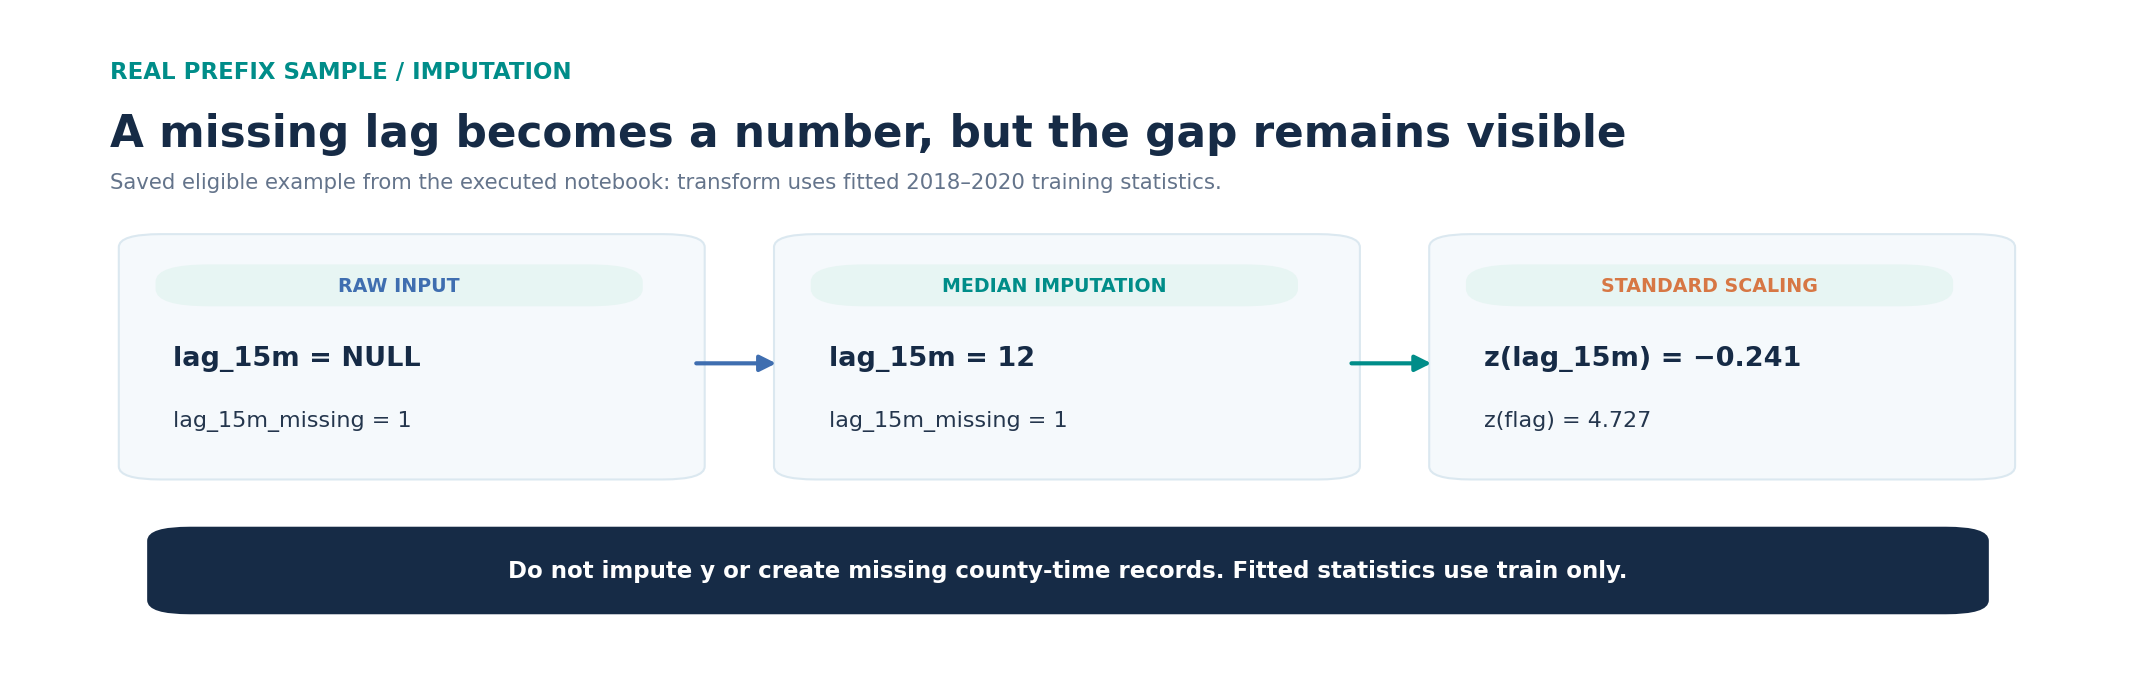

*Real prefix-row null → fitted-median → z-score illustration.*

<a id="task2-county-modeling"></a>
### Primary modeling cohort: three full-year counties, independently prepared

The earlier illustrative preparation is fitted on January-prefix training rows, and its fitted statistics must **not** be reused on the full-year county modeling cohort. This section creates/checks the separate 2018–2021 county modeling input with the same 13 ordered features and **fits preprocessing on county training rows only**. Its outcome is for Task 3; it never opens 2022.

In [14]:
if MODE == 'memory':
    county_candidate = audit_labels(county_gold)
else:
    county_candidate = read_frame(spark, county_locations['label_audit'])

for lag_feature in ['lag_15m', 'lag_60m', 'delta_60m']:
    county_candidate = county_candidate.withColumn(
        lag_feature + '_missing', F.col(lag_feature).isNull().cast('double')
    )

# Keep only complete positive-current anchors in the authorized development splits.
county_prepared = county_candidate.filter(
    F.col('candidate_y').isNotNull() & F.col('label_complete') &
    F.col('split').isin('train', 'validation') & (F.col('customers_out_t') > 0)
)
assert county_prepared.filter(F.year('timestamp') == 2022).count() == 0
assert X_COLUMNS == PREDICTORS + [name + '_missing' for name in ['lag_15m','lag_60m','delta_60m']]
assert county_prepared.select('candidate_y').distinct().count() == 2
county_prepared.groupBy('split', 'candidate_y').count().orderBy('split', 'candidate_y').show()
print('County cohort eligible train+validation rows:', county_prepared.count())

# An intentionally documented redundancy, not an accidental feature leak.
# Count disagreements between the two flags that should be identical.
flag_disagreements = county_prepared.filter(
    ~F.col('lag_60m_missing').eqNullSafe(F.col('delta_60m_missing'))
).count()
assert flag_disagreements == 0
print('Identical missingness flags (lag60/delta60):', flag_disagreements, 'disagreements')
print('Retain the 13-feature frozen baseline for fair Task 3 comparison; evaluate alternatives via ablation.')
# Import the same allowlist that the classifier will require.
from gridrescue.modeling import FEATURE_COLUMNS
assert X_COLUMNS == FEATURE_COLUMNS
assert county_prepared.groupBy('fips_code', 'timestamp').count().filter('count > 1').limit(1).count() == 0

+----------+-----------+------+
|     split|candidate_y| count|
+----------+-----------+------+
|     train|          0|192804|
|     train|          1|110987|
|validation|          0| 68730|
|validation|          1| 33719|
+----------+-----------+------+



County cohort eligible train+validation rows: 406240


Identical missingness flags (lag60/delta60): 0 disagreements
Retain the 13-feature frozen baseline for fair Task 3 comparison; evaluate alternatives via ablation.


### Train-only county preprocessing demonstration

Task 2 used **Spark Median Imputer → VectorAssembler → StandardScaler** for the reproducible preparation example. The final scikit-learn pipeline in Task 3 refits the **equivalent preprocessing concepts inside each chronological fold**; numerical standard-deviation conventions can differ slightly between Spark and scikit-learn. Never prefit Task 2's full training transform and then cross-validate those already transformed rows. The final Streamlit app must load the exact persisted Task 3 pipeline, not recreate these statistics.

In [15]:
# Reuse an existing verified county Spark preparation where possible; otherwise fit
# a separate educational county train-only Spark pipeline. This does not train ML models.
county_preparation_path = county_locations['artifacts'] / 'preparation'
if MODE != 'memory' and county_preparation_path.exists():
    county_preparation = load_preparation(county_preparation_path)
else:
    county_preparation = fit_preparation(county_prepared, X_COLUMNS)

assert [type(stage).__name__ for stage in county_preparation.stages] == [
    'ImputerModel', 'VectorAssembler', 'StandardScalerModel'
]
county_transformed = county_preparation.transform(county_prepared)
county_transformed.groupBy('split').count().show()
# Validate all county feature vectors, not just the first example.
from pyspark.ml.functions import vector_to_array
vectors = county_transformed.select(vector_to_array('scaled_features').alias('features'))
bad_vector = (F.size('features') != len(X_COLUMNS)) | F.exists(
    'features', lambda value: value.isNull() | F.isnan(value) | (F.abs(value) == F.lit(float('inf')))
)
county_vector_check = vectors.agg(F.count('*').alias('rows'),
                                  F.sum(bad_vector.cast('int')).alias('invalid_vectors')).first()
assert county_vector_check.rows == 406_240 and county_vector_check.invalid_vectors == 0
display(pd.DataFrame([county_vector_check.asDict()]))

training_stats = county_preparation.stages[-1]
county_fitted_stats = pd.DataFrame({
    'feature': X_COLUMNS,
    'training_mean_after_imputation': list(training_stats.mean),
    'training_std': list(training_stats.std),
})
display(county_fitted_stats)
print('Validation rows transformed using county training-only statistics; no future or test rows used.')

+----------+------+
|     split| count|
+----------+------+
|validation|102449|
|     train|303791|
+----------+------+



rows  invalid_vectors
0  406240                0

feature  training_mean_after_imputation   training_std
0        customers_out_t                         865.353      2,209.591
1                lag_15m                         864.498      2,208.546
2                lag_60m                         863.943      2,207.345
3              delta_60m                          -0.023      1,502.838
4       rolling_mean_60m                         865.298      2,066.232
5   rolling_variance_60m                     611,802.401 20,509,655.665
6      history_slots_60m                           4.989          0.141
7               hour_utc                          11.496          6.921
8            weekday_utc                           3.994          2.000
9              month_utc                           6.538          3.441
10       lag_15m_missing                           0.002          0.047
11       lag_60m_missing                           0.003          0.059
12     delta_60m_missing                           0.003          0.059

Validation rows transformed using county training-only statistics; no future or test rows used.


### County preprocessing handoff to Task 3

The persisted Task 3 artifact will contain a **scikit-learn `Pipeline`** with an imputer, scaler and trained estimator because each time-aware CV fold must independently learn preprocessing. Task 2 validates the source features/label and demonstrates Spark preparation, while Task 3 reconstructs per-fold preprocessing from **untransformed, 13-column county rows**. This prevents leakage and keeps the future app's input contract identical.

<a id="task2-county-summary"></a>
### Three-county Task 2 summary — verified artifacts

**What / why:** show the actual experimental cohort separately from the prefix teaching examples. **How:** read saved audit counts, eligible predictor null counts and training-fitted JSON statistics, and cross-check them against verified reload evidence. **Implementation:** pipeline.fit_preparation; storage.save_preparation; scripts/verify_persistence.py. No refitting or additional Spark scan is needed.

In [16]:
# Read verified artifacts only: no refit and no source/holdout scan.
# Read independent evidence that every saved vector matched the reloaded Spark stages.
county_proof=json.loads((ROOT/'reports/persistence_validation.json').read_text())
assert county_proof['status']=='VERIFIED'
county_paths=scope_paths(ROOT,'county',county_proof['storage_backend'])
county_report=json.loads((county_paths['report']/'audit.json').read_text())
county_saved=json.loads((county_paths['artifacts']/'preparation/preparation.json').read_text())
verified_county=county_proof['scopes']['county']
assert verified_county['original_fitted_statistics_equal']
# Compare medians, means and sample standard deviations with the county audit.
fit_stats=county_report['preparation_statistics']
names=fit_stats['feature_order']
assert names==X_COLUMNS==county_saved['imputer']['input_cols']
assert fit_stats['medians']==county_saved['imputer']['medians']
assert fit_stats['mean']==county_saved['scaler']['mean'] and fit_stats['sample_std']==county_saved['scaler']['std']
# Cross-check labeled rows independently in the split ledger and persistence report.
eligible_counts={row['split']:row['count'] for row in county_report['eligible_preparation_counts']}
split_rows=[]
for split in ['train','validation']:
    groups=[r for r in county_report['label_summary'] if r['split']==split and r['candidate_y'] in (0,1)]
    positive=sum(r['count'] for r in groups if r['candidate_y']==1)
    negative=sum(r['count'] for r in groups if r['candidate_y']==0)
    assert positive+negative==eligible_counts[split]==verified_county['split_rows'][split]
    split_rows.append({'split':split,'source years':', '.join(str(y) for y in sorted({r['year'] for r in groups})),
        'eligible rows':positive+negative,'positive':positive,'negative':negative,'positive prevalence':f'{positive/(positive+negative):.2%}'})
display(pd.DataFrame(split_rows))
assert fit_stats['training_rows']==eligible_counts['train']
total_eligible=sum(eligible_counts.values())
assert total_eligible==verified_county['rows']
raw_nulls=county_report['content_roundtrips']['prepared_features']['source_null_counts']
statistics=pd.DataFrame([{'feature':name,'eligible raw nulls':raw_nulls[name],
    'eligible raw null %':f'{raw_nulls[name]/total_eligible:.2%}','training median':fit_stats['medians'][name],
    'training mean':fit_stats['mean'][i],'training sample std':fit_stats['sample_std'][i]} for i,name in enumerate(names)])
display(statistics)
display(Markdown(f"**Three-county cohort only:** {total_eligible:,} eligible development anchors; preprocessing was fitted on {fit_stats['training_rows']:,} training anchors, never on validation. Null counts above cover eligible train + validation predictors before imputation; fitted statistics use training only. {verified_county['rows_exercising_missing_history']:,} eligible rows exercise missing-history handling in the verified reload. No county rows are merged into the January-prefix worked examples."))
display(Markdown('**Artifact sources:** reports/windows/county/audit.json; artifacts/windows/county/preparation/preparation.json; reports/persistence_validation.json. This is a descriptive summary of existing verified preparation, not a reusable preprocessing fit for earlier CV folds. No classifier or 2022 data is accessed.'))

split      source years  eligible rows  positive  negative  \
0       train  2018, 2019, 2020         303791    110987    192804   
1  validation              2021         102449     33719     68730   

  positive prevalence  
0              36.53%  
1              32.91%

feature  eligible raw nulls eligible raw null %  \
0        customers_out_t                   0               0.00%   
1                lag_15m                 802               0.20%   
2                lag_60m                1296               0.32%   
3              delta_60m                1296               0.32%   
4       rolling_mean_60m                   0               0.00%   
5   rolling_variance_60m                   0               0.00%   
6      history_slots_60m                   0               0.00%   
7               hour_utc                   0               0.00%   
8            weekday_utc                   0               0.00%   
9              month_utc                   0               0.00%   
10       lag_15m_missing                   0               0.00%   
11       lag_60m_missing                   0               0.00%   
12     delta_60m_missing                   0               0.00%   

    training median  training mean  training sample std  
0           259.000        865.353            2,209.591  
1           259.000        864.498            2,208.546  
2           259.000        863.943            2,207.345  
3            -3.000         -0.023            1,502.838  
4           293.200        865.298            2,066.232  
5         1,608.560    611,802.401       20,509,655.665  
6             5.000          4.989                0.141  
7            11.000         11.496                6.921  
8             4.000          3.994                2.000  
9             7.000          6.538                3.441  
10            0.000          0.002                0.047  
11            0.000          0.003                0.059  
12            0.000          0.003                0.059

**Three-county cohort only:** 406,240 eligible development anchors; preprocessing was fitted on 303,791 training anchors, never on validation. Null counts above cover eligible train + validation predictors before imputation; fitted statistics use training only. 1,952 eligible rows exercise missing-history handling in the verified reload. No county rows are merged into the January-prefix worked examples.

**Artifact sources:** reports/windows/county/audit.json; artifacts/windows/county/preparation/preparation.json; reports/persistence_validation.json. This is a descriptive summary of existing verified preparation, not a reusable preprocessing fit for earlier CV folds. No classifier or 2022 data is accessed.

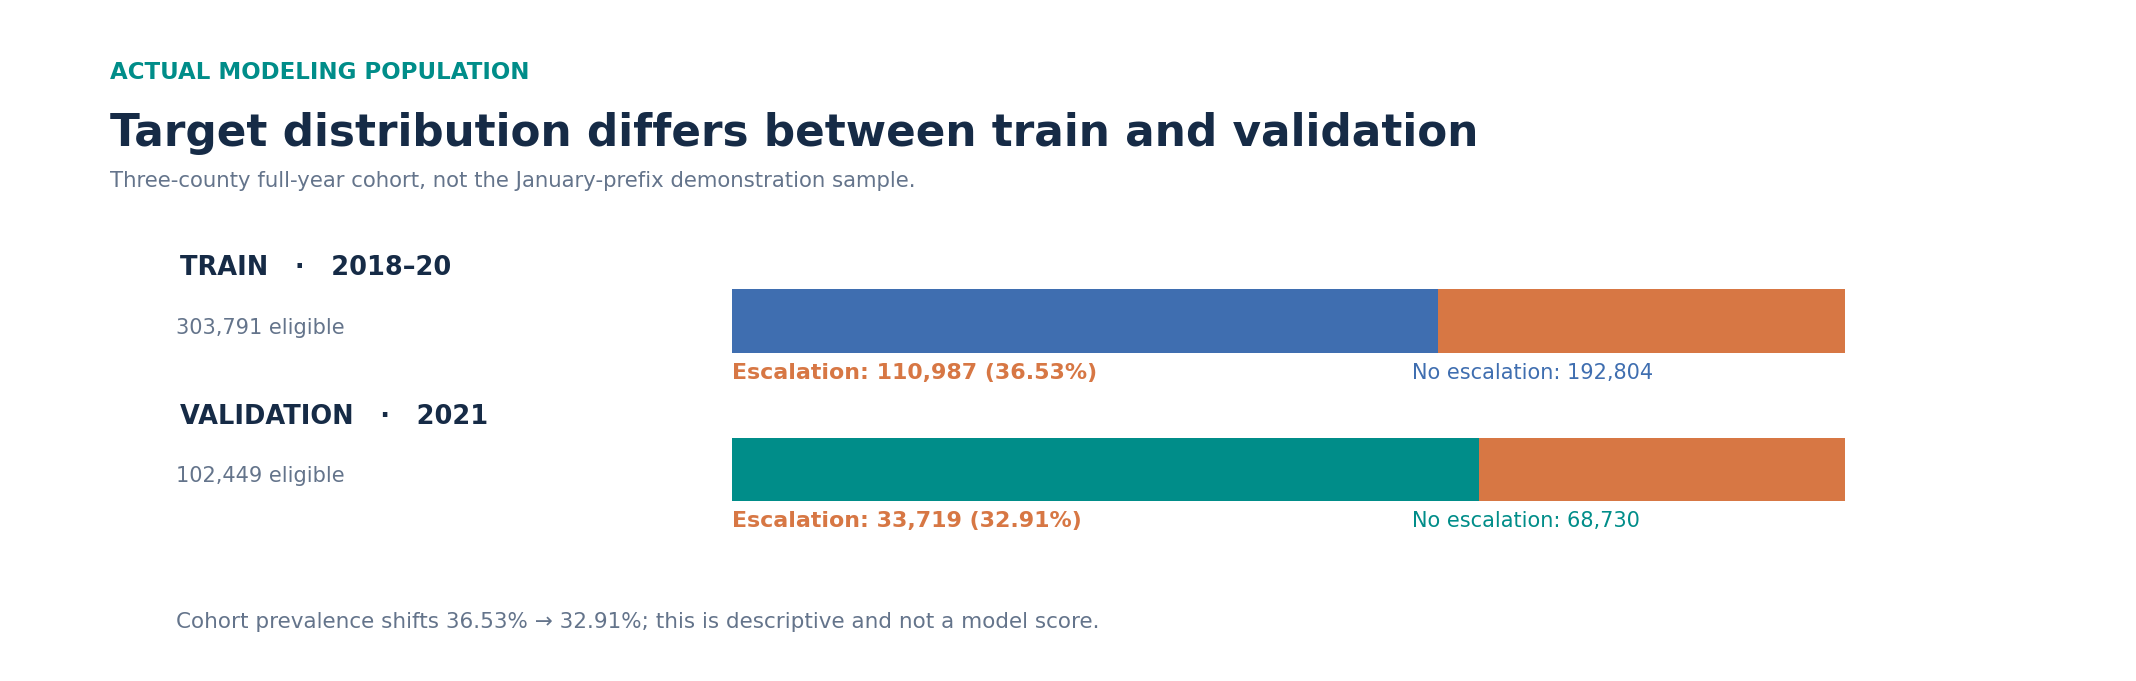

*The real three-county modeling cohort and its distinct 2021 validation prevalence.*

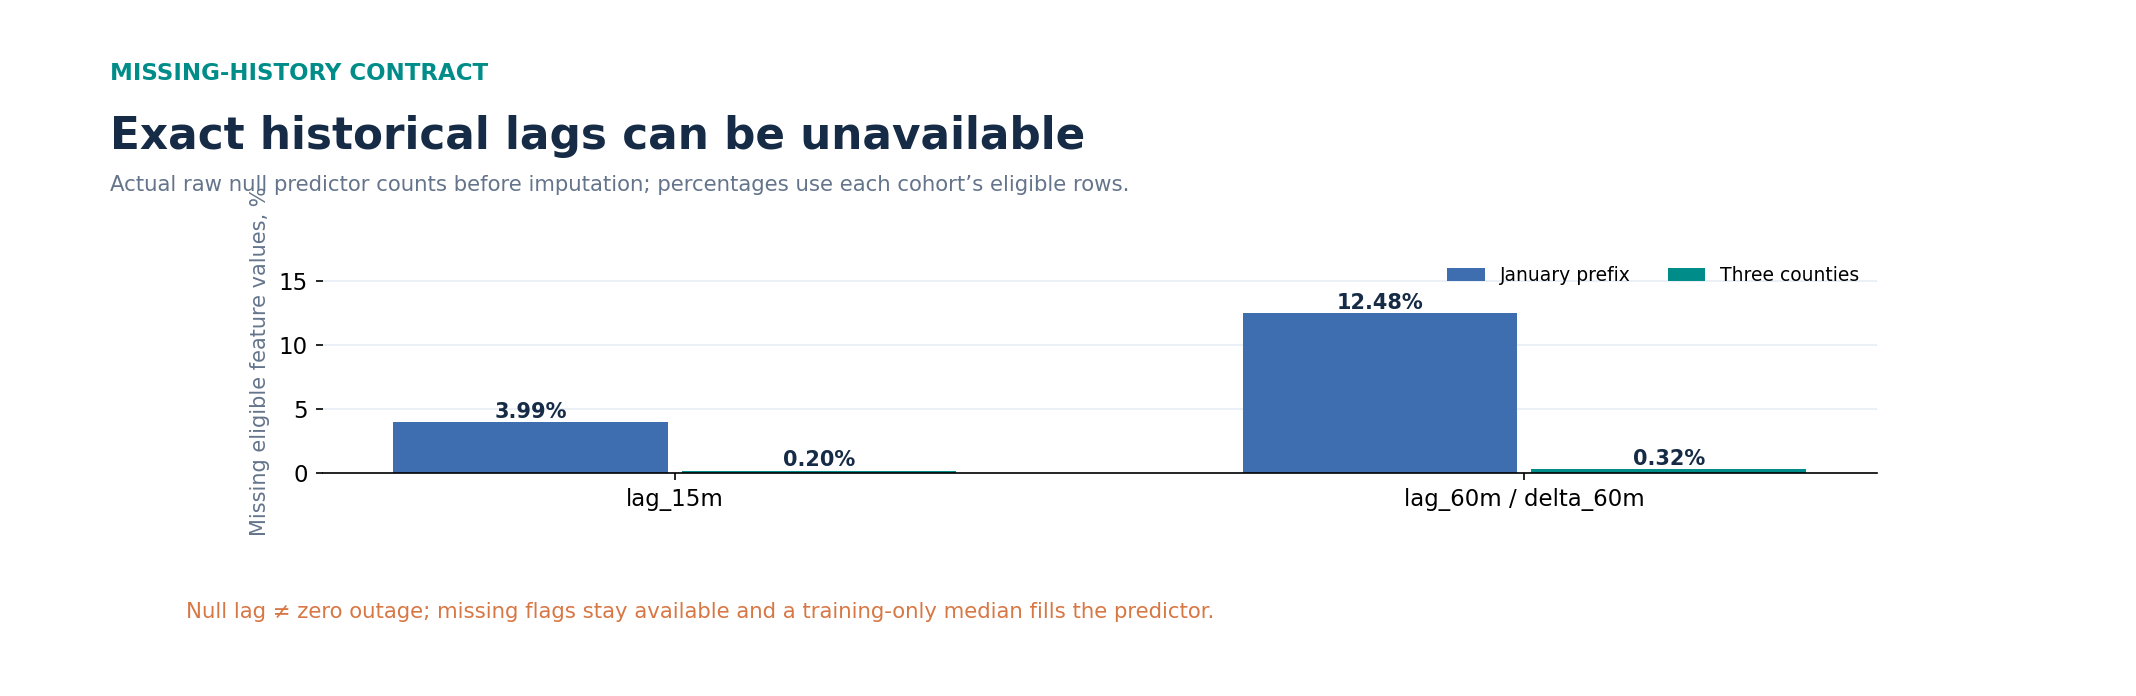

*Pre-imputation feature null rates by scope; missing labels are excluded, not imputed.*

<a id="task2-checks"></a>
## 04 Final Data Checks
### Check Outputs
Display actual prepared counts and bounded examples. Model fitting is intentionally absent.

**What / why:** Inspect final predictor rows, dimensions and split sizes. Verify what a later model would actually receive without fitting a classifier.

**How:** Preparation transforms train and validation using the same training-fitted stages and ordered allowlist.

**Implementation:** `Spark PipelineModel.transform`.

In [17]:
print('Candidate prepared rows:',prepared.count(),'X columns:',len(X_COLUMNS))
show_table(prepared.select('split','fips_code','timestamp','customers_out_t','lag_15m','lag_60m','lag_15m_missing','lag_60m_missing','candidate_y').orderBy('timestamp','fips_code'),3)
if preparation is not None:
    transformed.groupBy('split').count().show()
    print('Vector dimension:',transformed.select('scaled_features').first()[0].size)

# Collect three sorted vectors to show all thirteen positions in order.
vector_rows=transformed.orderBy('timestamp','fips_code').select('scaled_features').limit(3).collect()
display(pd.DataFrame([list(row.scaled_features) for row in vector_rows],columns=X_COLUMNS))
print('Rows above are three real 13-position prepared vectors, in the exact feature order.')

Candidate prepared rows: 163386 X columns: 13


*Scope: Prefix: 400,000 raw rows, 2018–2021; up to 3 displayed rows.*

split fips_code            timestamp  customers_out_t  lag_15m  lag_60m  \
0  train     01073  2018-01-01 00:00:00                6      NaN      NaN   
1  train     01117  2018-01-01 00:00:00                2      NaN      NaN   
2  train     01125  2018-01-01 00:00:00                5      NaN      NaN   

   lag_15m_missing  lag_60m_missing  candidate_y  
0            1.000            1.000            1  
1            1.000            1.000            0  
2            1.000            1.000            1

+----------+------+
|     split| count|
+----------+------+
|validation| 53601|
|     train|109785|
+----------+------+

Vector dimension: 13


customers_out_t  lag_15m  lag_60m  delta_60m  rolling_mean_60m  \
0           -0.254   -0.241   -0.233      0.008            -0.265   
1           -0.260   -0.241   -0.233      0.008            -0.272   
2           -0.256   -0.241   -0.233      0.008            -0.267   

   rolling_variance_60m  history_slots_60m  hour_utc  weekday_utc  month_utc  \
0                -0.054             -3.840    -1.630       -1.466      0.000   
1                -0.054             -3.840    -1.630       -1.466      0.000   
2                -0.054             -3.840    -1.630       -1.466      0.000   

   lag_15m_missing  lag_60m_missing  delta_60m_missing  
0            4.727            2.578              2.578  
1            4.727            2.578              2.578  
2            4.727            2.578              2.578

Rows above are three real 13-position prepared vectors, in the exact feature order.


### Validate Features
Validate finite imputed values and vector consistency. Raw missing predictors are expected before
imputation; missing y values are excluded, not filled. Candidate label presence does not authorize training.

**What / why:** Check imputed columns and vector finiteness/dimensions. A vector containing NaN/inf or the wrong dimension is unsuitable for later learning.

**How:** Spark exists checks every vector entry; size enforces thirteen positions. Missing y was excluded rather than imputed.

**Implementation:** `pyspark.ml.functions.vector_to_array and Spark higher-order functions`.

In [18]:
if preparation is not None:
    imputed = preparation.stages[0].getOutputCols()
    # Compare missing counts before and after imputation using one aggregated row.
    missing_summary=transformed.agg(*([F.sum((F.col(c).isNull()|F.isnan(c)).cast('long')).alias('raw_'+str(i)) for i,c in enumerate(X_COLUMNS)]+[F.sum((F.col(c).isNull()|F.isnan(c)).cast('long')).alias('imputed_'+str(i)) for i,c in enumerate(imputed)])).first().asDict()
    display(pd.DataFrame([{'feature':name,'eligible raw missing':missing_summary['raw_'+str(i)],'after imputation missing':missing_summary['imputed_'+str(i)]} for i,name in enumerate(X_COLUMNS)]))
    bad = transformed.filter(F.expr(' OR '.join(f'`{c}` IS NULL OR isnan(`{c}`)' for c in imputed))).count()
    assert bad==0
    print('All imputed predictor columns pass null/NaN checks for this subset.')
    from pyspark.ml.functions import vector_to_array
    # Convert Spark ML vectors to arrays so Spark can check each entry.
    arrays=transformed.select(vector_to_array('scaled_features').alias('x'))
    # Flag vectors containing any null, NaN or infinite entry.
    nonfinite=arrays.filter(F.exists('x',lambda v:v.isNull()|F.isnan(v)|(F.abs(v)==F.lit(float('inf'))))).count()
    bad_dimensions=arrays.filter(F.size('x')!=len(X_COLUMNS)).count()
    assert nonfinite==0 and bad_dimensions==0
    validation={'mode':MODE,'transformed_rows':transformed.count(),'vector_dimension':len(X_COLUMNS),
                'nonfinite_vectors':nonfinite,'wrong_dimension_vectors':bad_dimensions,
                'split_rows':{r['split']:r['count'] for r in transformed.groupBy('split').count().collect()},
                'fitted_pipeline_reloaded': MODE != 'memory'}
    (ROOT/'reports/preparation_validation.json').write_text(json.dumps(validation,indent=2),encoding='utf-8')
    display(validation)
print('Input feature list identical for train and validation:',X_COLUMNS)

feature  eligible raw missing  after imputation missing
0        customers_out_t                     0                         0
1                lag_15m                  6514                         0
2                lag_60m                 20394                         0
3              delta_60m                 20394                         0
4       rolling_mean_60m                     0                         0
5   rolling_variance_60m                     0                         0
6      history_slots_60m                     0                         0
7               hour_utc                     0                         0
8            weekday_utc                     0                         0
9              month_utc                     0                         0
10       lag_15m_missing                     0                         0
11       lag_60m_missing                     0                         0
12     delta_60m_missing                     0                         0

All imputed predictor columns pass null/NaN checks for this subset.


{'mode': 'arrow-local',
 'transformed_rows': 163386,
 'vector_dimension': 13,
 'nonfinite_vectors': 0,
 'wrong_dimension_vectors': 0,
 'split_rows': {'validation': 53601, 'train': 109785},
 'fitted_pipeline_reloaded': True}

Input feature list identical for train and validation: ['customers_out_t', 'lag_15m', 'lag_60m', 'delta_60m', 'rolling_mean_60m', 'rolling_variance_60m', 'history_slots_60m', 'hour_utc', 'weekday_utc', 'month_utc', 'lag_15m_missing', 'lag_60m_missing', 'delta_60m_missing']


### Save Preparation
In-memory execution computes all analytical outputs and fits preparation without saving Spark
artifacts. Parquet execution loads saved preparation. The separate fresh-process persistence
report compares every persisted vector against the reloaded pipeline output. Presence alone
is not treated as verification. Scientific approval is limited to the three-county experiment.

**What / why:** Verify saved data and fitted preprocessing separately. An artifact path alone does not prove a usable save/reload.

**How:** A separate Python process reloads both real scopes and compares saved vectors against reloaded Spark preprocessing, including null-bearing inputs and exact fitted statistics.

**Implementation:** `scripts/verify_persistence.py; reports/persistence_validation.json`.

In [19]:
paths={'bronze':LOCATIONS['bronze'],'silver':SILVER,'gold':GOLD,'label_audit':LABELS,
       'prepared_features':BASE/'prepared_features','preparation':BASE/'preparation'}
for name,p in paths.items():
    print(name, 'PRESENT' if p.exists() else 'ABSENT / BLOCKED', str(p.relative_to(ROOT)))
persistence_path=ROOT/'reports/persistence_validation.json'
persistence=json.loads(persistence_path.read_text()) if persistence_path.exists() else {'status':'UNVERIFIED'}
display(pd.DataFrame([dict(scope=scope,rows=item['rows'],dimensions=item['vector_dimension'],exact_vector_mismatches=item['exact_vector_mismatches'],fitted_statistics_equal=item.get('original_fitted_statistics_equal'),missing_history_rows=item.get('rows_exercising_missing_history')) for scope,item in persistence.get('scopes',{}).items()]))
print('Full schema, null, timestamp and every-value comparison evidence: reports/persistence_validation.json')
print('Windows Arrow-local is a storage workaround. Native Hadoop writing remains blocked; no unsafe binary was installed.')
if MODE!='memory':
    assert persistence['status']=='VERIFIED'
display({'scope':audit.get('scope'),'counts':audit.get('counts'),'splits':audit.get('splits')})
county_audit=county_scope_audit
display(pd.DataFrame(county_audit['eligible_preparation_counts']))
display(pd.DataFrame(county_audit['coverage_by_county_year']))
prefix_counts={r['split']:r['count'] for r in audit['eligible_preparation_counts']}
county_counts={r['split']:r['count'] for r in county_audit['eligible_preparation_counts']}
display(Markdown(f"**Interpretation:** eligible prefix anchors: {prefix_counts}; selected-county anchors: {county_counts}. These cohorts differ substantially in temporal coverage. 2022 test rows are not materialized here; zero loaded test rows does not mean no test data exists. Preprocessing uses only prefix training rows. This execution mode is {MODE}; separate persistence status: {persistence['status']}."))
print('Explain-back: where did the lag come from? Which rows got no y? Which years fitted the scaler? Why is 2022 untouched?')
print('Task 2 ends at preparation. Task 3 has its own development-only execution.')
recomputed.unpersist()
spark.stop()

bronze PRESENT data\windows\bronze\sample
silver PRESENT data\windows\silver\sample
gold PRESENT data\windows\gold\sample\features
label_audit PRESENT data\windows\gold\sample\label_audit
prepared_features PRESENT artifacts\windows\sample\prepared_features
preparation PRESENT artifacts\windows\sample\preparation


scope    rows  dimensions  exact_vector_mismatches  \
0  sample  163386          13                        0   
1  county  406240          13                        0   

   fitted_statistics_equal  missing_history_rows  
0                     True                 21597  
1                     True                  1952

Full schema, null, timestamp and every-value comparison evidence: reports/persistence_validation.json
Windows Arrow-local is a storage workaround. Native Hadoop writing remains blocked; no unsafe binary was installed.


{'scope': 'FIRST 100000 source rows per development year 2018-2021; NOT full population; 2022 untouched',
 'counts': {'raw': 400000,
  'invalid': 66369,
  'exact_duplicates_removed': 0,
  'conflict_rows': 0,
  'silver': 333631},
 'splits': [{'split': 'validation',
   'all_anchors': 98618,
   'complete_candidate_anchors': 53601},
  {'split': 'train',
   'all_anchors': 235013,
   'complete_candidate_anchors': 109785}]}

split   count
0  validation  102449
1       train  303791

fips_code       county       state  year  observed_anchors  observed_days  \
0      06037  Los Angeles  California  2018             34254            365   
1      12086   Miami-Dade     Florida  2018             34673            365   
2      48201       Harris       Texas  2018             34644            365   
3      06037  Los Angeles  California  2019             34797            365   
4      12086   Miami-Dade     Florida  2019             34673            365   
5      48201       Harris       Texas  2019             34735            365   
6      06037  Los Angeles  California  2020             35011            366   
7      12086   Miami-Dade     Florida  2020             34925            366   
8      48201       Harris       Texas  2020             34905            366   
9      06037  Los Angeles  California  2021             34823            365   
10     12086   Miami-Dade     Florida  2021             34757            365   
11     48201       Harris       Texas  2021             34743            365   

                  first                 last  eligible  positive  negative  
0   2018-01-01 00:00:00  2018-12-31 00:00:00     32580     14063     18517  
1   2018-01-01 00:00:00  2018-12-31 00:00:00     33686     10863     22823  
2   2018-01-01 00:00:00  2018-12-31 00:00:00     33535     11209     22326  
3   2019-01-01 00:00:00  2019-12-31 00:00:00     34339     15828     18511  
4   2019-01-01 00:00:00  2019-12-31 00:00:00     32854      9664     23190  
5   2019-01-01 00:00:00  2019-12-31 00:00:00     34156     11276     22880  
6   2020-01-01 00:00:00  2020-12-31 00:00:00     34773     15799     18974  
7   2020-01-01 00:00:00  2020-12-31 00:00:00     34047     10338     23709  
8   2020-01-01 00:00:00  2020-12-31 00:00:00     33821     11947     21874  
9   2021-01-01 00:00:00  2021-12-31 00:00:00     34476     14820     19656  
10  2021-01-01 00:00:00  2021-12-31 00:00:00     34057     10113     23944  
11  2021-01-01 00:00:00  2021-12-31 00:00:00     33916      8786     25130

**Interpretation:** eligible prefix anchors: {'validation': 53601, 'train': 109785}; selected-county anchors: {'validation': 102449, 'train': 303791}. These cohorts differ substantially in temporal coverage. 2022 test rows are not materialized here; zero loaded test rows does not mean no test data exists. Preprocessing uses only prefix training rows. This execution mode is arrow-local; separate persistence status: VERIFIED.

Explain-back: where did the lag come from? Which rows got no y? Which years fitted the scaler? Why is 2022 untouched?
Task 2 ends at preparation. Task 3 has its own development-only execution.


#### Understanding the code — saving and reloading

The Spark artifact stores fitted medians, vector order and scaler statistics. Reload reconstructs fitted stages and verifies their output against the saved vectors. **TA question:** Does loading refit the scaler? **Answer:** It restores learned statistics and applies them with `transform()`.

> **Verification evidence vs native Hadoop**  
> The Arrow-local save/reload workaround passed bounded exact-content and fitted-statistic checks; the native Windows Hadoop writer is still blocked and national-scale persistence is unverified.